In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!git clone https://github.com/shubham000111222/HR-CNN-Replication.git

Cloning into 'HR-CNN-Replication'...
remote: Enumerating objects: 24, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 24 (delta 3), reused 24 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (24/24), 567.03 KiB | 8.72 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [ ]:
%cd HR-CNN-Replication

/content/HR-CNN-Replication


In [ ]:
!ls

data  notebooks  README.md  requirements.txt  src


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!find /content/drive/MyDrive -maxdepth 4 -type d | grep -i "weedcube"

In [ ]:
!find /content/drive/MyDrive -type f -name "*.npy" | head -50

In [ ]:
!find /content/drive/MyDrive -maxdepth 3 -type d | head -100

/content/drive/MyDrive
/content/drive/MyDrive/Colab Notebooks
/content/drive/MyDrive/Classroom
/content/drive/MyDrive/Classroom/CSE 7th Semester (2023 BATCH) 1
/content/drive/MyDrive/Classroom/ISP - (BTech CSE 4th year), cssb 425 CS2
/content/drive/MyDrive/project
/content/drive/MyDrive/project/build
/content/drive/MyDrive/project/build/keylogger
/content/drive/MyDrive/final_project
/content/drive/MyDrive/HR-CNN-DATA
/content/drive/MyDrive/HR-CNN-DATA/processed
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia
/content/drive/MyDrive/HR-CNN-DATA/processed/redroot_pigweed
/content/drive/MyDrive/HR-CNN-DATA/processed/soybean
/content/drive/MyDrive/HR-CNN-DATA/processed/waterhemp
/content/drive/MyDrive/HR-CNN-DATA/processed/canola
/content/drive/MyDrive/HR-CNN-DATA/processed/ragweed
/content/drive/MyDrive/HR-CNN-DATA/processed/sugarbeet


In [ ]:
!find "/content/drive/MyDrive/HR-CNN-DATA/processed" -type f -name "*.npy" | wc -l

160


In [ ]:
!cp -r "/content/drive/MyDrive/HR-CNN-DATA/processed" "./data/"

In [ ]:
!find "./data/processed" -type f -name "*.npy" | wc -l

160


In [ ]:
!find "./data/processed" -maxdepth 1 -mindepth 1 -type d

./data/processed/ragweed
./data/processed/sugarbeet
./data/processed/soybean
./data/processed/redroot_pigweed
./data/processed/canola
./data/processed/kochia
./data/processed/waterhemp


In [ ]:
from pathlib import Path
import json

for split in ["train", "val", "test"]:
    path = Path("data/splits") / f"{split}.json"

    with open(path, "r") as f:
        records = json.load(f)

    print(f"{split}: {len(records)} samples")

    missing = [
        r["file"]
        for r in records
        if not Path(r["file"]).exists()
    ]

    print(f"Missing files: {len(missing)}")

train: 96 samples
Missing files: 96
val: 32 samples
Missing files: 32
test: 32 samples
Missing files: 32


In [ ]:
import json

with open("data/splits/train.json", "r") as f:
    records = json.load(f)

print(records[0])

{'file': 'data\\processed\\canola\\canola_9.npy', 'class': 'canola', 'label': 0}


In [ ]:
import json
from pathlib import Path

for split in ["train", "val", "test"]:
    path = Path("data/splits") / f"{split}.json"

    with open(path, "r") as f:
        records = json.load(f)

    for record in records:
        record["file"] = record["file"].replace("\\", "/")

    with open(path, "w") as f:
        json.dump(records, f, indent=2)

    print(f"Fixed: {split}.json")

Fixed: train.json
Fixed: val.json
Fixed: test.json


In [ ]:
from pathlib import Path
import json

for split in ["train", "val", "test"]:
    path = Path("data/splits") / f"{split}.json"

    with open(path, "r") as f:
        records = json.load(f)

    missing = [
        r["file"]
        for r in records
        if not Path(r["file"]).exists()
    ]

    print(f"{split}: {len(records)} samples | Missing files: {len(missing)}")

train: 96 samples | Missing files: 0
val: 32 samples | Missing files: 0
test: 32 samples | Missing files: 0


In [ ]:
import sys
import tensorflow as tf

sys.path.append("/content/HR-CNN-Replication/src")

from models.hr_cnn import build_hr_cnn

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

model = build_hr_cnn(
    input_shape=(100, 100, 54, 1),
    num_classes=7
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nModel ready.")
print("Parameters:", model.count_params())

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Model ready.
Parameters: 12620519


In [ ]:
%cd /content/HR-CNN-Replication

import sys
sys.path.append("/content/HR-CNN-Replication/src")

import tensorflow as tf
from data_loader import load_split
from augmentation import augment_cube
from models.hr_cnn import build_hr_cnn

# Load one small batch of training data
X_train, y_train = load_split("train")

# Augment only the first 2 samples for the smoke test
X_aug = []
y_aug = []

for cube, label in zip(X_train[:2], y_train[:2]):
    for aug_cube in augment_cube(cube):
        X_aug.append(aug_cube)
        y_aug.append(label)

X_aug = tf.convert_to_tensor(X_aug, dtype=tf.float32)
X_aug = X_aug[..., None]

y_aug = tf.keras.utils.to_categorical(y_aug, 7)

print("Smoke-test training data:", X_aug.shape)
print("GPU:", tf.config.list_physical_devices("GPU"))

model = build_hr_cnn(
    input_shape=(100, 100, 54, 1),
    num_classes=7
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nStarting 2-epoch smoke test...\n")

history = model.fit(
    X_aug,
    y_aug,
    batch_size=1,
    epochs=2,
    verbose=1
)

print("\nSmoke test completed successfully.")

/content/HR-CNN-Replication

Loading train split...
Number of samples: 96
Loaded X shape: (96, 100, 100, 54)
Loaded y shape: (96,)
Smoke-test training data: (22, 100, 100, 54, 1)
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Starting 2-epoch smoke test...

Epoch 1/2
22/22 ━━━━━━━━━━━━━━━━━━━━ 21s 65ms/step - accuracy: 1.0000 - loss: 0.1263
Epoch 2/2
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 1.0000 - loss: 0.1157

Smoke test completed successfully.


In [ ]:
%%writefile /content/HR-CNN-Replication/src/train_model.py

import sys
from pathlib import Path

import tensorflow as tf
import numpy as np

sys.path.append("/content/HR-CNN-Replication/src")

from data_loader import load_split
from augmentation import augment_cube
from models.hr_cnn import build_hr_cnn


# ============================================================
# Configuration
# ============================================================

NUM_CLASSES = 7
INPUT_SHAPE = (100, 100, 54, 1)

BATCH_SIZE = 1
EPOCHS = 1
LEARNING_RATE = 0.0001

MODEL_DIR = Path("/content/HR-CNN-Replication/results/models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42


# ============================================================
# Augmentation generator
# ============================================================

def augmented_generator(X, y):
    """
    Generates augmented hyperspectral cubes one at a time.

    Each original cube produces 11 versions:
    original + rotations + flips + translations.
    """

    indices = np.arange(len(X))

    while True:

        # Shuffle original samples every epoch
        rng = np.random.default_rng(SEED)
        rng.shuffle(indices)

        for index in indices:

            cube = X[index]
            label = y[index]

            augmented_cubes = augment_cube(cube)

            # Shuffle augmentations so training sees
            # different transformations in different order
            rng.shuffle(augmented_cubes)

            for aug_cube in augmented_cubes:

                aug_cube = aug_cube.astype(np.float32)
                aug_cube = aug_cube[..., np.newaxis]

                label_one_hot = tf.keras.utils.to_categorical(
                    label,
                    NUM_CLASSES
                )

                yield aug_cube, label_one_hot


# ============================================================
# Dataset creation
# ============================================================

def create_training_dataset(X_train, y_train):

    output_signature = (
        tf.TensorSpec(
            shape=(100, 100, 54, 1),
            dtype=tf.float32
        ),
        tf.TensorSpec(
            shape=(NUM_CLASSES,),
            dtype=tf.float32
        )
    )

    dataset = tf.data.Dataset.from_generator(
        lambda: augmented_generator(X_train, y_train),
        output_signature=output_signature
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


def create_validation_dataset(X_val, y_val):

    y_val = tf.keras.utils.to_categorical(
        y_val,
        NUM_CLASSES
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            X_val[..., np.newaxis],
            y_val
        )
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# ============================================================
# Main training
# ============================================================

def main():

    print("=" * 70)
    print("HR-CNN MEMORY-EFFICIENT TRAINING")
    print("=" * 70)

    print("\nGPU:")
    print(tf.config.list_physical_devices("GPU"))

    # --------------------------------------------------------
    # Load data
    # --------------------------------------------------------

    print("\n[1] Loading training data...")

    X_train, y_train = load_split("train")

    print("\n[2] Loading validation data...")

    X_val, y_val = load_split("val")

    print("\n[3] Loading test data...")

    X_test, y_test = load_split("test")

    print("\nOriginal training samples:", len(X_train))
    print("Validation samples:", len(X_val))
    print("Test samples:", len(X_test))

    # 96 original × 11 augmentations
    steps_per_epoch = len(X_train) * 11 // BATCH_SIZE

    print("\nAugmentations per original sample: 11")
    print("Training samples per epoch:", steps_per_epoch)

    # --------------------------------------------------------
    # Create datasets
    # --------------------------------------------------------

    print("\n[4] Creating training dataset...")

    train_dataset = create_training_dataset(
        X_train,
        y_train
    )

    print("Training dataset created.")

    print("\n[5] Creating validation dataset...")

    val_dataset = create_validation_dataset(
        X_val,
        y_val
    )

    print("Validation dataset created.")

    # --------------------------------------------------------
    # Build model
    # --------------------------------------------------------

    print("\n[6] Building HR-CNN...")

    model = build_hr_cnn(
        input_shape=INPUT_SHAPE,
        num_classes=NUM_CLASSES
    )

    model.summary()

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------

    print("\n[7] Compiling model...")

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # --------------------------------------------------------
    # Learning-rate decay
    # --------------------------------------------------------

    lr_scheduler = tf.keras.callbacks.LearningRateScheduler(
        lambda epoch, lr:
        LEARNING_RATE * (0.98 ** (epoch / 1000)),
        verbose=0
    )

    # --------------------------------------------------------
    # Callbacks
    # --------------------------------------------------------

    checkpoint_path = (
        MODEL_DIR / "hr_cnn_best.keras"
    )

    callbacks = [

        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=20,
            mode="max",
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor="val_accuracy",
            mode="max",
            save_best_only=True,
            verbose=1
        ),

        lr_scheduler
    ]

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("STARTING TRAINING")
    print("=" * 70)

    print("Batch size:", BATCH_SIZE)
    print("Maximum epochs:", EPOCHS)
    print("Learning rate:", LEARNING_RATE)
    print("Optimizer: Adam")
    print("Loss: Categorical Cross-Entropy")
    print("Early stopping patience: 20")

    history = model.fit(

        train_dataset,

        validation_data=val_dataset,

        epochs=EPOCHS,

        steps_per_epoch=steps_per_epoch,

        callbacks=callbacks,

        verbose=1
    )

    # --------------------------------------------------------
    # Test evaluation
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("EVALUATING ON TEST SET")
    print("=" * 70)

    y_test_cat = tf.keras.utils.to_categorical(
        y_test,
        NUM_CLASSES
    )

    test_dataset = tf.data.Dataset.from_tensor_slices(
        (
            X_test[..., np.newaxis],
            y_test_cat
        )
    )

    test_dataset = test_dataset.batch(BATCH_SIZE)

    test_loss, test_accuracy = model.evaluate(
        test_dataset,
        verbose=1
    )

    print("\nTest Loss:", round(test_loss, 4))
    print("Test Accuracy:", round(test_accuracy, 4))

    # --------------------------------------------------------
    # Save final model
    # --------------------------------------------------------

    final_model_path = (
        MODEL_DIR / "hr_cnn_final.keras"
    )

    model.save(final_model_path)

    print("\nBest model:")
    print(checkpoint_path)

    print("\nFinal model:")
    print(final_model_path)

    print("\nTraining completed successfully!")

    return history


if __name__ == "__main__":
    main()

Overwriting /content/HR-CNN-Replication/src/train_model.py


In [ ]:
%cd /content/HR-CNN-Replication
!python src/train_model.py

/content/HR-CNN-Replication
HR-CNN MEMORY-EFFICIENT TRAINING

GPU:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

[1] Loading training data...

Loading train split...
Number of samples: 96
Loaded X shape: (96, 100, 100, 54)
Loaded y shape: (96,)

[2] Loading validation data...

Loading val split...
Number of samples: 32
Loaded X shape: (32, 100, 100, 54)
Loaded y shape: (32,)

[3] Loading test data...

Loading test split...
Number of samples: 32
Loaded X shape: (32, 100, 100, 54)
Loaded y shape: (32,)

Original training samples: 96
Validation samples: 32
Test samples: 32

Augmentations per original sample: 11
Training samples per epoch: 1056

[4] Creating training dataset...
2026-09-12 01:30:51.911981: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1789176651.913392   17267 gpu_device.cc:2020] Created device /job:l

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

DRIVE_RESULTS = Path("/content/drive/MyDrive/HR-CNN-DATA/results")
DRIVE_RESULTS.mkdir(parents=True, exist_ok=True)

print("Persistent results folder:")
print(DRIVE_RESULTS)

Persistent results folder:
/content/drive/MyDrive/HR-CNN-DATA/results


In [ ]:
%%writefile /content/HR-CNN-Replication/src/train_model.py

import sys
from pathlib import Path

import tensorflow as tf
import numpy as np

sys.path.append("/content/HR-CNN-Replication/src")

from data_loader import load_split
from augmentation import augment_cube
from models.hr_cnn import build_hr_cnn


# ============================================================
# Configuration
# ============================================================

NUM_CLASSES = 7
INPUT_SHAPE = (100, 100, 54, 1)

BATCH_SIZE = 1
EPOCHS = 400
LEARNING_RATE = 0.0001

SEED = 42

# Save directly to Google Drive
MODEL_DIR = Path(
    "/content/drive/MyDrive/HR-CNN-DATA/results/models"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL = MODEL_DIR / "hr_cnn_best.keras"
FINAL_MODEL = MODEL_DIR / "hr_cnn_final.keras"


# ============================================================
# Augmentation generator
# ============================================================

def augmented_generator(X, y):

    rng = np.random.default_rng(SEED)

    indices = np.arange(len(X))

    while True:

        rng.shuffle(indices)

        for index in indices:

            cube = X[index]
            label = y[index]

            augmented_cubes = augment_cube(cube)

            rng.shuffle(augmented_cubes)

            for aug_cube in augmented_cubes:

                aug_cube = aug_cube.astype(np.float32)
                aug_cube = aug_cube[..., np.newaxis]

                label_one_hot = tf.keras.utils.to_categorical(
                    label,
                    NUM_CLASSES
                )

                yield aug_cube, label_one_hot


# ============================================================
# Training dataset
# ============================================================

def create_training_dataset(X_train, y_train):

    output_signature = (

        tf.TensorSpec(
            shape=(100, 100, 54, 1),
            dtype=tf.float32
        ),

        tf.TensorSpec(
            shape=(NUM_CLASSES,),
            dtype=tf.float32
        )
    )

    dataset = tf.data.Dataset.from_generator(
        lambda: augmented_generator(X_train, y_train),
        output_signature=output_signature
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# ============================================================
# Validation dataset
# ============================================================

def create_validation_dataset(X_val, y_val):

    y_val = tf.keras.utils.to_categorical(
        y_val,
        NUM_CLASSES
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (
            X_val[..., np.newaxis],
            y_val
        )
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# ============================================================
# Main
# ============================================================

def main():

    print("=" * 70)
    print("HR-CNN TRAINING — GOOGLE DRIVE CHECKPOINT VERSION")
    print("=" * 70)

    print("\nGPU:")
    print(tf.config.list_physical_devices("GPU"))

    # --------------------------------------------------------
    # Load data
    # --------------------------------------------------------

    print("\n[1] Loading training data...")

    X_train, y_train = load_split("train")

    print("\n[2] Loading validation data...")

    X_val, y_val = load_split("val")

    print("\n[3] Loading test data...")

    X_test, y_test = load_split("test")

    print("\nOriginal training samples:", len(X_train))
    print("Validation samples:", len(X_val))
    print("Test samples:", len(X_test))

    # 96 × 11 = 1056
    steps_per_epoch = (
        len(X_train) * 11 // BATCH_SIZE
    )

    print("\nAugmentations per sample: 11")
    print("Steps per epoch:", steps_per_epoch)

    # --------------------------------------------------------
    # Dataset
    # --------------------------------------------------------

    print("\n[4] Creating training dataset...")

    train_dataset = create_training_dataset(
        X_train,
        y_train
    )

    print("Training dataset created.")

    print("\n[5] Creating validation dataset...")

    val_dataset = create_validation_dataset(
        X_val,
        y_val
    )

    print("Validation dataset created.")

    # --------------------------------------------------------
    # Model
    # --------------------------------------------------------

    print("\n[6] Building HR-CNN...")

    model = build_hr_cnn(
        input_shape=INPUT_SHAPE,
        num_classes=NUM_CLASSES
    )

    print("HR-CNN created successfully.")

    # --------------------------------------------------------
    # Optimizer
    # --------------------------------------------------------

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    )

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    # --------------------------------------------------------
    # Callbacks
    # --------------------------------------------------------

    callbacks = [

        # Save the best model directly to Drive
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(BEST_MODEL),
            monitor="val_accuracy",
            mode="max",
            save_best_only=True,
            verbose=1
        ),

        # Stop if validation accuracy stops improving
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=20,
            mode="max",
            restore_best_weights=True,
            verbose=1
        ),

        # Paper-inspired learning-rate decay
        tf.keras.callbacks.LearningRateScheduler(
            lambda epoch, lr:
            LEARNING_RATE * (0.98 ** (epoch / 1000)),
            verbose=0
        )
    ]

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("STARTING FULL TRAINING")
    print("=" * 70)

    print("Maximum epochs:", EPOCHS)
    print("Batch size:", BATCH_SIZE)
    print("Learning rate:", LEARNING_RATE)
    print("Best model location:")
    print(BEST_MODEL)

    history = model.fit(

        train_dataset,

        validation_data=val_dataset,

        epochs=EPOCHS,

        steps_per_epoch=steps_per_epoch,

        callbacks=callbacks,

        verbose=1
    )

    # --------------------------------------------------------
    # Test
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("EVALUATING ON TEST SET")
    print("=" * 70)

    y_test_cat = tf.keras.utils.to_categorical(
        y_test,
        NUM_CLASSES
    )

    test_dataset = tf.data.Dataset.from_tensor_slices(
        (
            X_test[..., np.newaxis],
            y_test_cat
        )
    )

    test_dataset = test_dataset.batch(BATCH_SIZE)

    test_loss, test_accuracy = model.evaluate(
        test_dataset,
        verbose=1
    )

    print("\nTest Loss:", round(test_loss, 4))
    print("Test Accuracy:", round(test_accuracy, 4))

    # --------------------------------------------------------
    # Save final model
    # --------------------------------------------------------

    model.save(FINAL_MODEL)

    print("\nFinal model saved to:")
    print(FINAL_MODEL)

    print("\nBest model saved to:")
    print(BEST_MODEL)

    print("\n" + "=" * 70)
    print("TRAINING COMPLETED")
    print("=" * 70)


if __name__ == "__main__":
    main()

Overwriting /content/HR-CNN-Replication/src/train_model.py


In [ ]:
!ls -lh /content/drive/MyDrive/HR-CNN-DATA/results/models

ls: cannot access '/content/drive/MyDrive/HR-CNN-DATA/results/models': No such file or directory


In [ ]:
from pathlib import Path

path = Path("/content/drive/MyDrive/HR-CNN-DATA/results/models")
path.mkdir(parents=True, exist_ok=True)

print("Created:", path)

Created: /content/drive/MyDrive/HR-CNN-DATA/results/models


In [ ]:
!ls -lh /content/drive/MyDrive/HR-CNN-DATA/results/models

total 0


In [ ]:
%cd /content/HR-CNN-Replication

!python src/train_model.py

/content/HR-CNN-Replication
HR-CNN TRAINING — GOOGLE DRIVE CHECKPOINT VERSION

GPU:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

[1] Loading training data...

Loading train split...
Number of samples: 96
Loaded X shape: (96, 100, 100, 54)
Loaded y shape: (96,)

[2] Loading validation data...

Loading val split...
Number of samples: 32
Loaded X shape: (32, 100, 100, 54)
Loaded y shape: (32,)

[3] Loading test data...

Loading test split...
Number of samples: 32
Loaded X shape: (32, 100, 100, 54)
Loaded y shape: (32,)

Original training samples: 96
Validation samples: 32
Test samples: 32

Augmentations per sample: 11
Steps per epoch: 1056

[4] Creating training dataset...
2026-09-12 01:43:01.458641: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1789177381.460186   20566 gpu_device.cc:2020] Created device /job:loca

In [ ]:
%cd /content/HR-CNN-Replication

import sys
sys.path.append("/content/HR-CNN-Replication/src")

import tensorflow as tf
import numpy as np
from pathlib import Path

from data_loader import load_split
from models.hr_cnn import build_hr_cnn

# --------------------------------------------------
# Configuration
# --------------------------------------------------

NUM_CLASSES = 7
INPUT_SHAPE = (100, 100, 54, 1)

MODEL_PATH = "/content/drive/MyDrive/HR-CNN-DATA/results/models/hr_cnn_best.keras"

# --------------------------------------------------
# Load test data
# --------------------------------------------------

X_test, y_test = load_split("test")

X_test = X_test[..., np.newaxis]

print("Test data shape:", X_test.shape)
print("Test labels shape:", y_test.shape)

# --------------------------------------------------
# Load best model
# --------------------------------------------------

print("\nLoading best HR-CNN model...")

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully.")

# --------------------------------------------------
# Evaluate
# --------------------------------------------------

test_loss, test_accuracy = model.evaluate(
    X_test,
    tf.keras.utils.to_categorical(y_test, NUM_CLASSES),
    batch_size=1,
    verbose=1
)

print("\n" + "=" * 60)
print("BEST MODEL TEST RESULTS")
print("=" * 60)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

/content/HR-CNN-Replication

Loading test split...
Number of samples: 32
Loaded X shape: (32, 100, 100, 54)
Loaded y shape: (32,)
Test data shape: (32, 100, 100, 54, 1)
Test labels shape: (32,)

Loading best HR-CNN model...
Model loaded successfully.
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8438 - loss: 0.5707

BEST MODEL TEST RESULTS
Test Loss     : 0.5707
Test Accuracy : 0.8438
Test Accuracy : 84.38%


Generating predictions...
32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step

Test Accuracy: 84.38%

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

         Canola     1.0000    0.7500    0.8571         4
         Kochia     1.0000    1.0000    1.0000         4
      Sugarbeet     1.0000    0.2500    0.4000         4
Redroot Pigweed     1.0000    0.8750    0.9333         8
        Ragweed     1.0000    1.0000    1.0000         4
      Waterhemp     0.5000    1.0000    0.6667         4
        Soybean     0.8000    1.0000    0.8889         4

       accuracy                         0.8438        32
      macro avg     0.9000    0.8393    0.8209        32
   weighted avg     0.9125    0.8438    0.8349        32


Confusion Matrix:
[[3 0 0 0 0 1 0]
 [0 4 0 0 0 0 0]
 [0 0 1 0 0 2 1]
 [0 0 0 7 0 1 0]
 [0 0 0 0 4 0 0]
 [0 0 0 0 0 4 0]
 [0 0 0 0 0 0 4]]


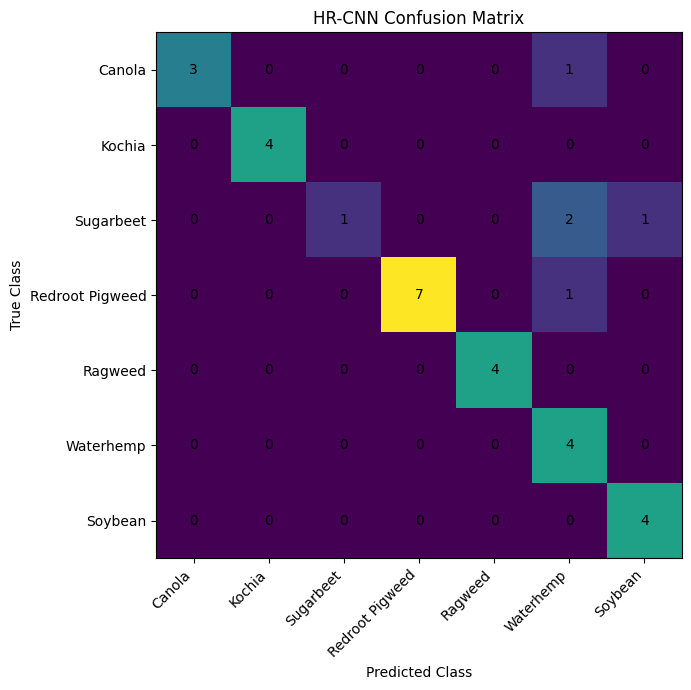

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

import matplotlib.pyplot as plt

# Class names
class_names = [
    "Canola",
    "Kochia",
    "Sugarbeet",
    "Redroot Pigweed",
    "Ragweed",
    "Waterhemp",
    "Soybean"
]

# --------------------------------------------------
# Predictions
# --------------------------------------------------

print("Generating predictions...")

predictions = model.predict(
    X_test,
    batch_size=1,
    verbose=1
)

y_pred = np.argmax(predictions, axis=1)

# --------------------------------------------------
# Accuracy
# --------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\nTest Accuracy:", f"{accuracy * 100:.2f}%")

# --------------------------------------------------
# Classification report
# --------------------------------------------------

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# --------------------------------------------------
# Confusion matrix
# --------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)

# --------------------------------------------------
# Plot confusion matrix
# --------------------------------------------------

plt.figure(figsize=(9, 7))

plt.imshow(cm)

plt.title("HR-CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(class_names)),
    class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

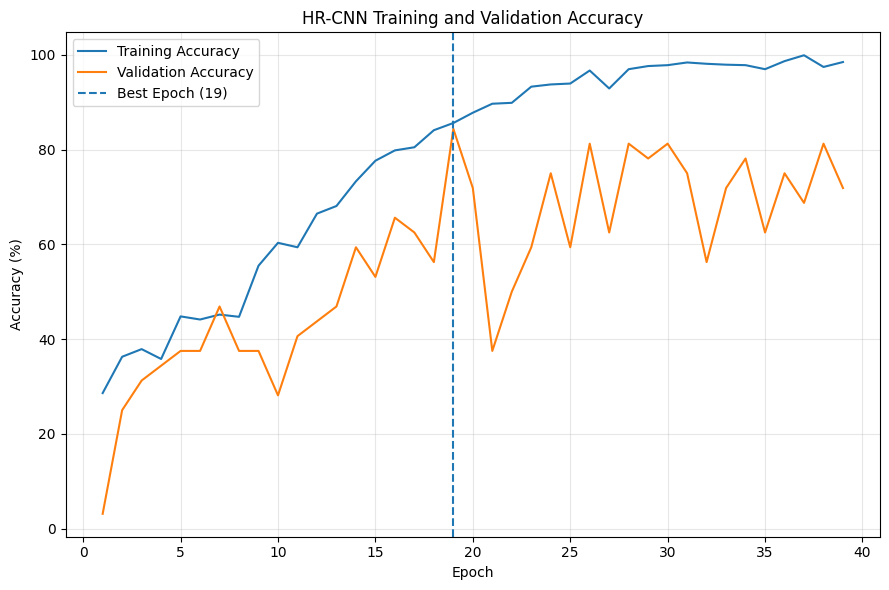

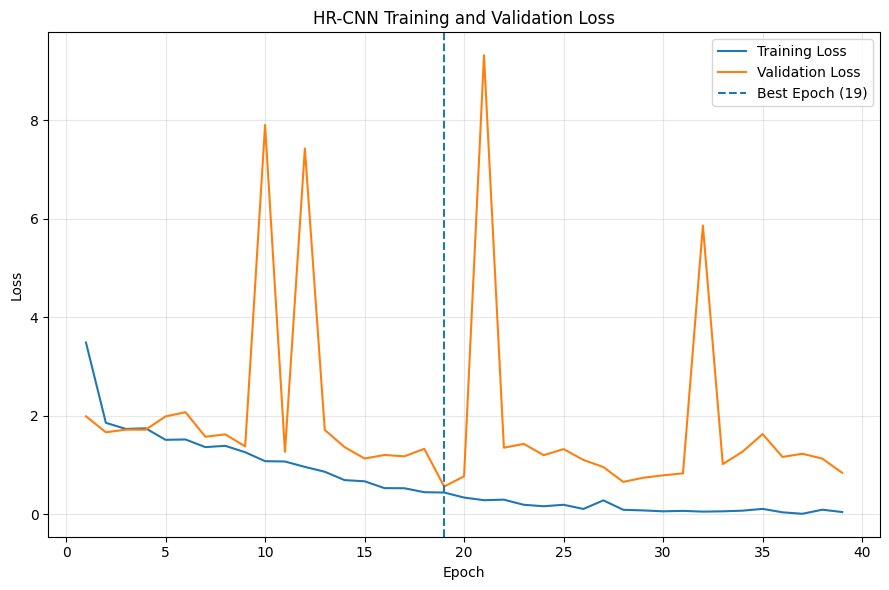

Saved:
/content/drive/MyDrive/HR-CNN-DATA/results/figures/hr_cnn_accuracy_curve.png
/content/drive/MyDrive/HR-CNN-DATA/results/figures/hr_cnn_loss_curve.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# ============================================================
# Recorded training history from the completed HR-CNN run
# ============================================================

epochs = np.arange(1, 40)

train_accuracy = [
    0.2860, 0.3627, 0.3788, 0.3580, 0.4479, 0.4413, 0.4517,
    0.4470, 0.5549, 0.6032, 0.5938, 0.6648, 0.6809, 0.7330,
    0.7765, 0.7983, 0.8049, 0.8409, 0.8561, 0.8778, 0.8968,
    0.8987, 0.9328, 0.9375, 0.9394, 0.9669, 0.9290, 0.9697,
    0.9763, 0.9782, 0.9839, 0.9811, 0.9792, 0.9782, 0.9697,
    0.9867, 0.9991, 0.9744, 0.9848
]

val_accuracy = [
    0.0312, 0.2500, 0.3125, 0.3438, 0.3750, 0.3750, 0.4688,
    0.3750, 0.3750, 0.2812, 0.4062, 0.4375, 0.4688, 0.5938,
    0.5312, 0.6562, 0.6250, 0.5625, 0.8438, 0.7188, 0.3750,
    0.5000, 0.5938, 0.7500, 0.5938, 0.8125, 0.6250, 0.8125,
    0.7812, 0.8125, 0.7500, 0.5625, 0.7188, 0.7812, 0.6250,
    0.7500, 0.6875, 0.8125, 0.7188
]

train_loss = [
    3.4910, 1.8611, 1.7367, 1.7488, 1.5154, 1.5228, 1.3672,
    1.3937, 1.2637, 1.0823, 1.0752, 0.9660, 0.8673, 0.6972,
    0.6738, 0.5350, 0.5325, 0.4523, 0.4457, 0.3434, 0.2902,
    0.3009, 0.1967, 0.1673, 0.1968, 0.1124, 0.2866, 0.0949,
    0.0826, 0.0643, 0.0730, 0.0580, 0.0641, 0.0774, 0.1139,
    0.0442, 0.0139, 0.0970, 0.0498
]

val_loss = [
    1.9934, 1.6688, 1.7222, 1.7213, 1.9909, 2.0765, 1.5782,
    1.6263, 1.3830, 7.9063, 1.2712, 7.4294, 1.7157, 1.3660,
    1.1362, 1.2079, 1.1805, 1.3330, 0.5676, 0.7753, 9.3220,
    1.3554, 1.4330, 1.2036, 1.3269, 1.1067, 0.9629, 0.6610,
    0.7456, 0.7951, 0.8345, 5.8645, 1.0226, 1.2765, 1.6332,
    1.1684, 1.2329, 1.1345, 0.8456
]

# ============================================================
# Save directory
# ============================================================

results_dir = Path(
    "/content/drive/MyDrive/HR-CNN-DATA/results/figures"
)
results_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# Accuracy curve
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    epochs,
    np.array(train_accuracy) * 100,
    label="Training Accuracy"
)

plt.plot(
    epochs,
    np.array(val_accuracy) * 100,
    label="Validation Accuracy"
)

plt.axvline(
    19,
    linestyle="--",
    label="Best Epoch (19)"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("HR-CNN Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

accuracy_path = results_dir / "hr_cnn_accuracy_curve.png"
plt.savefig(accuracy_path, dpi=300)
plt.show()

# ============================================================
# Loss curve
# ============================================================

plt.figure(figsize=(9, 6))

plt.plot(
    epochs,
    train_loss,
    label="Training Loss"
)

plt.plot(
    epochs,
    val_loss,
    label="Validation Loss"
)

plt.axvline(
    19,
    linestyle="--",
    label="Best Epoch (19)"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("HR-CNN Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

loss_path = results_dir / "hr_cnn_loss_curve.png"
plt.savefig(loss_path, dpi=300)
plt.show()

print("Saved:")
print(accuracy_path)
print(loss_path)

In [ ]:
%cd /content/HR-CNN-Replication

!find data/raw -name "*.npy" | head -20

/content/HR-CNN-Replication
find: ‘data/raw’: No such file or directory


In [ ]:
%cd /content/HR-CNN-Replication

!git clone https://github.com/billygrahamram/WeedCube.git /content/WeedCube

/content/HR-CNN-Replication
Cloning into '/content/WeedCube'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 25 (delta 5), reused 2 (delta 2), pack-reused 19 (from 1)
Receiving objects: 100% (25/25), 948.46 KiB | 9.12 MiB/s, done.
Resolving deltas: 100% (10/10), done.


In [ ]:
!find /content/WeedCube -name "*.npy" | head -20

/content/HR-CNN-Replication
Model loaded successfully.

Loading test split...
Number of samples: 32
Loaded X shape: (32, 100, 100, 54)
Loaded y shape: (32,)
Last Conv3D layer: conv3d_19
Output shape: (None, 7, 7, 4, 256)

Correctly classified samples: 27

Sample index: 0
True class: Canola
Predicted class: Canola
Confidence: 60.96%
Grad-CAM shape: (7, 7, 4)


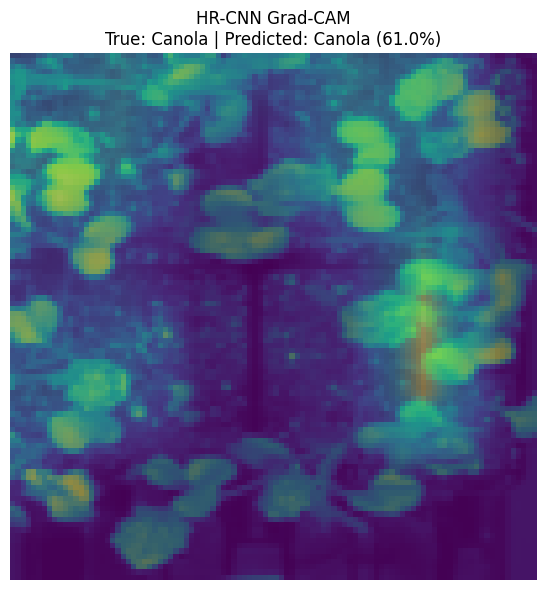

In [ ]:
%cd /content/HR-CNN-Replication

import sys
sys.path.append("/content/HR-CNN-Replication/src")

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from data_loader import load_split

# ============================================================
# Load best model
# ============================================================

MODEL_PATH = (
    "/content/drive/MyDrive/HR-CNN-DATA/"
    "results/models/hr_cnn_best.keras"
)

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully.")

# ============================================================
# Load test data
# ============================================================

X_test, y_test = load_split("test")

X_test_input = X_test[..., np.newaxis]

class_names = [
    "Canola",
    "Kochia",
    "Sugarbeet",
    "Redroot Pigweed",
    "Ragweed",
    "Waterhemp",
    "Soybean"
]

# ============================================================
# Find last Conv3D layer
# ============================================================

conv3d_layers = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Conv3D)
]

last_conv_layer = conv3d_layers[-1]

print("Last Conv3D layer:", last_conv_layer.name)
print("Output shape:", last_conv_layer.output.shape)

# ============================================================
# Create Grad-CAM model
# ============================================================

grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        last_conv_layer.output,
        model.output
    ]
)

# ============================================================
# Grad-CAM function
# ============================================================

def generate_gradcam(cube, true_label):

    input_tensor = tf.convert_to_tensor(
        cube[np.newaxis, ...],
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            input_tensor,
            training=False
        )

        predicted_class = tf.argmax(
            predictions[0]
        )

        class_score = predictions[
            0, predicted_class
        ]

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    # Average gradients over spatial/spectral dimensions
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2, 3)
    )

    # Weighted feature maps
    cam = tf.reduce_sum(
        conv_outputs * weights[:, tf.newaxis, tf.newaxis, tf.newaxis, :],
        axis=-1
    )

    cam = tf.nn.relu(cam)

    cam = cam[0].numpy()

    # Normalize
    if cam.max() > 0:
        cam = cam / cam.max()

    prediction = predictions[0].numpy()

    predicted_class = int(
        np.argmax(prediction)
    )

    confidence = float(
        prediction[predicted_class]
    )

    return cam, predicted_class, confidence


# ============================================================
# Select a correctly classified test sample
# ============================================================

predictions = model.predict(
    X_test_input,
    batch_size=1,
    verbose=0
)

y_pred = np.argmax(
    predictions,
    axis=1
)

correct_indices = np.where(
    y_pred == y_test
)[0]

print("\nCorrectly classified samples:", len(correct_indices))

# Pick the first correctly classified sample
sample_index = int(correct_indices[0])

cube = X_test[sample_index]
true_label = int(y_test[sample_index])

# ============================================================
# Generate Grad-CAM
# ============================================================

cam, predicted_class, confidence = generate_gradcam(
    cube,
    true_label
)

print("\nSample index:", sample_index)
print("True class:", class_names[true_label])
print("Predicted class:", class_names[predicted_class])
print("Confidence:", f"{confidence * 100:.2f}%")
print("Grad-CAM shape:", cam.shape)

# ============================================================
# Convert hyperspectral cube to 2D visualization
# ============================================================

# Average spectral information to create a 2D plant representation
spectral_mean = np.mean(
    cube,
    axis=2
)

# Reduce 3D Grad-CAM across spectral dimension
cam_2d = np.mean(
    cam,
    axis=2
)

# Resize Grad-CAM to original 100x100 image
cam_resized = tf.image.resize(
    cam_2d[..., np.newaxis],
    (100, 100)
).numpy().squeeze()

# Normalize again
if cam_resized.max() > 0:
    cam_resized = (
        cam_resized / cam_resized.max()
    )

# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(8, 6))

plt.imshow(
    spectral_mean,
    interpolation="nearest"
)

plt.imshow(
    cam_resized,
    alpha=0.45,
    interpolation="nearest"
)

plt.title(
    f"HR-CNN Grad-CAM\n"
    f"True: {class_names[true_label]} | "
    f"Predicted: {class_names[predicted_class]} "
    f"({confidence * 100:.1f}%)"
)

plt.axis("off")
plt.tight_layout()

plt.show()

/content/HR-CNN-Replication
Loading best model...

Loading test split...
Number of samples: 32
Loaded X shape: (32, 100, 100, 54)
Loaded y shape: (32,)
Model loaded.
Test data: (32, 100, 100, 54, 1)
Grad-CAM layer: conv3d_19

Selected examples:
Index 0: True=Canola, Predicted=Canola, Type=Correct
Index 4: True=Kochia, Predicted=Kochia, Type=Correct
Index 10: True=Sugarbeet, Predicted=Sugarbeet, Type=Correct
Index 12: True=Redroot Pigweed, Predicted=Redroot Pigweed, Type=Correct
Index 8: True=Sugarbeet, Predicted=Waterhemp, Type=Misclassified


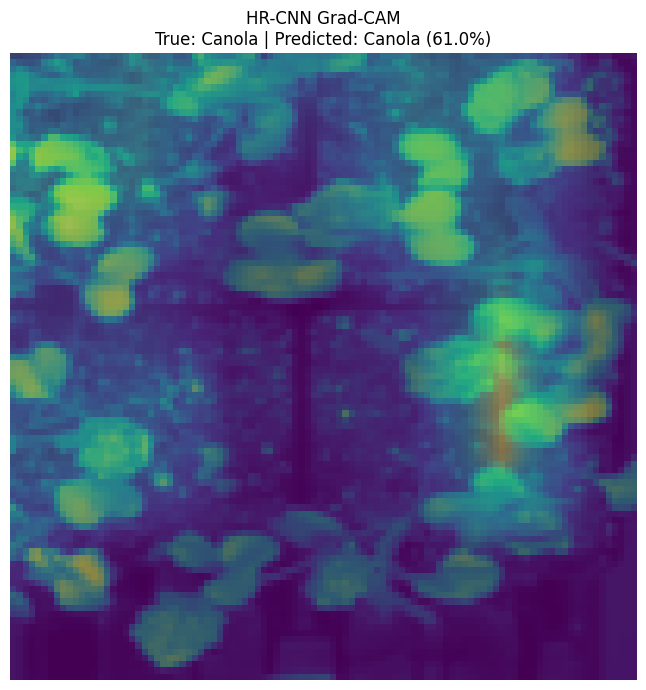

Saved: /content/drive/MyDrive/HR-CNN-DATA/results/figures/gradcam/0_Canola_correct.png


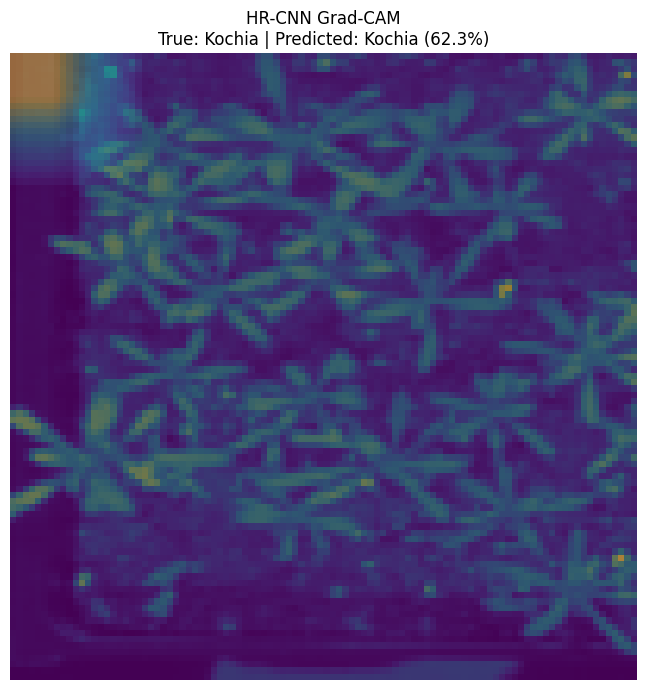

Saved: /content/drive/MyDrive/HR-CNN-DATA/results/figures/gradcam/4_Kochia_correct.png


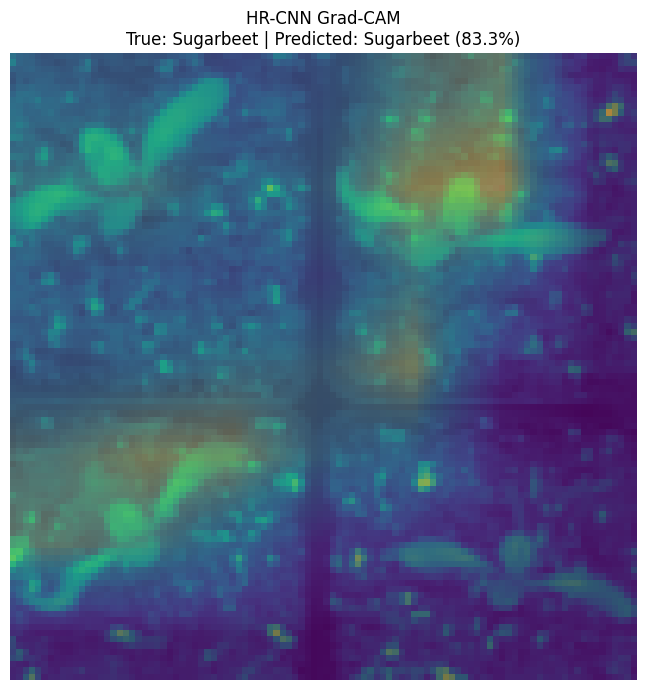

Saved: /content/drive/MyDrive/HR-CNN-DATA/results/figures/gradcam/10_Sugarbeet_correct.png


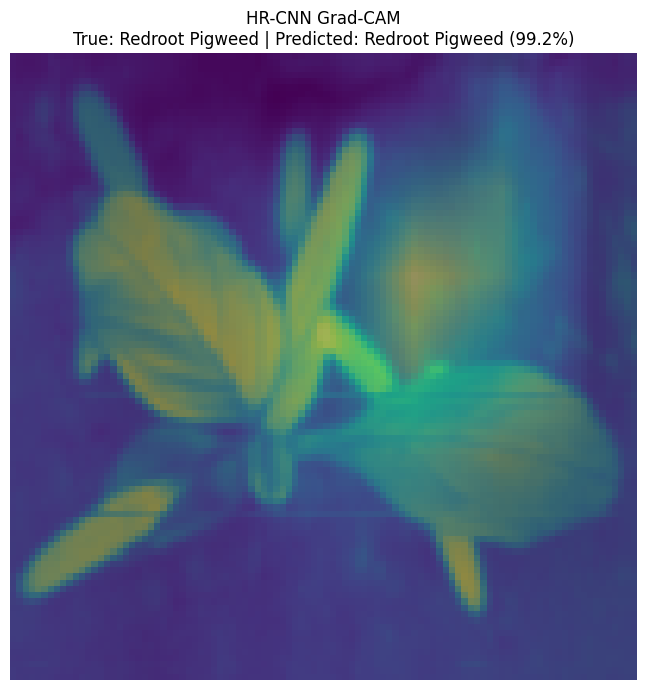

Saved: /content/drive/MyDrive/HR-CNN-DATA/results/figures/gradcam/12_Redroot_Pigweed_correct.png


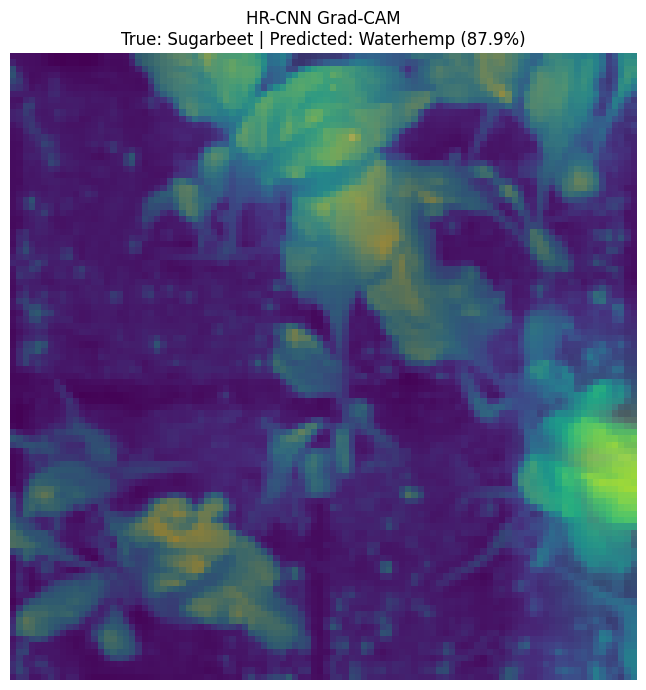

Saved: /content/drive/MyDrive/HR-CNN-DATA/results/figures/gradcam/8_Sugarbeet_misclassified.png


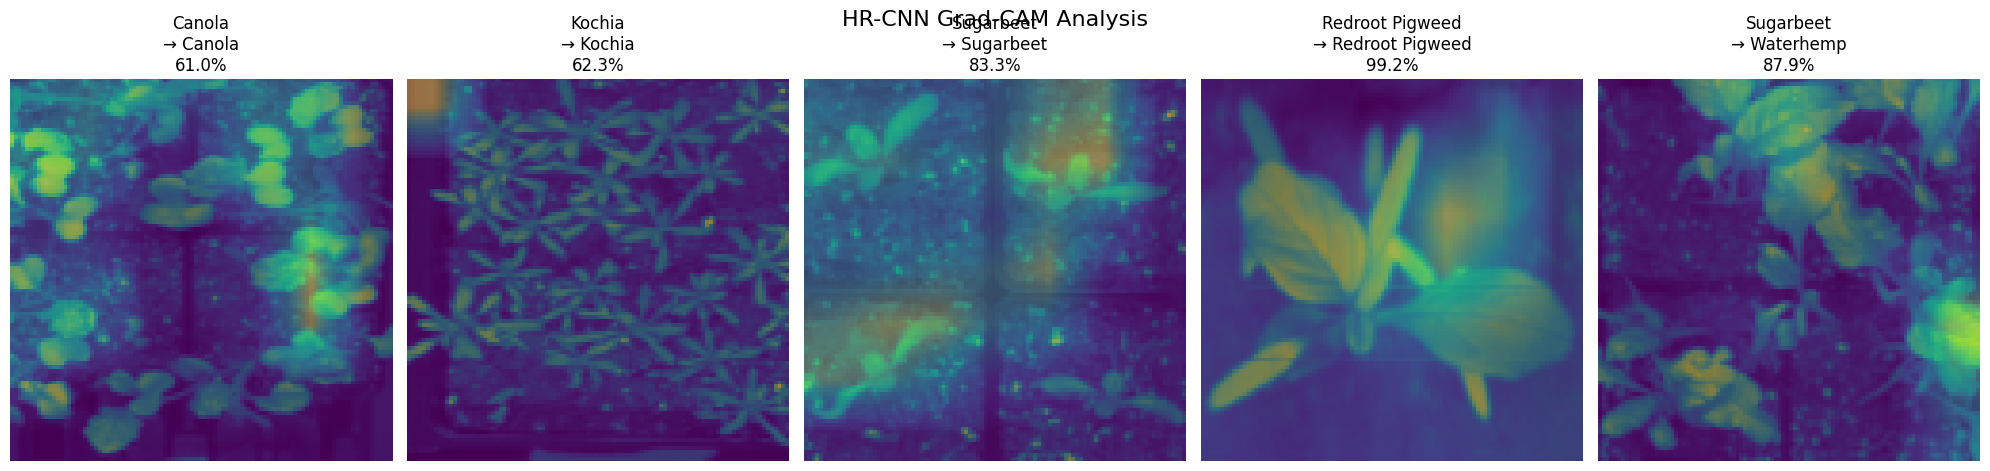


Combined figure saved to:
/content/drive/MyDrive/HR-CNN-DATA/results/figures/gradcam/hr_cnn_gradcam_examples.png


In [ ]:
%cd /content/HR-CNN-Replication

import sys
sys.path.append("/content/HR-CNN-Replication/src")

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from data_loader import load_split

# ============================================================
# Configuration
# ============================================================

MODEL_PATH = (
    "/content/drive/MyDrive/HR-CNN-DATA/"
    "results/models/hr_cnn_best.keras"
)

SAVE_DIR = Path(
    "/content/drive/MyDrive/HR-CNN-DATA/"
    "results/figures/gradcam"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

class_names = [
    "Canola",
    "Kochia",
    "Sugarbeet",
    "Redroot Pigweed",
    "Ragweed",
    "Waterhemp",
    "Soybean"
]

# ============================================================
# Load model and test data
# ============================================================

print("Loading best model...")

model = tf.keras.models.load_model(MODEL_PATH)

X_test, y_test = load_split("test")

X_test_input = X_test[..., np.newaxis]

print("Model loaded.")
print("Test data:", X_test_input.shape)

# ============================================================
# Predictions
# ============================================================

predictions = model.predict(
    X_test_input,
    batch_size=1,
    verbose=0
)

y_pred = np.argmax(predictions, axis=1)

# ============================================================
# Find last Conv3D layer
# ============================================================

conv_layers = [
    layer for layer in model.layers
    if isinstance(layer, tf.keras.layers.Conv3D)
]

last_conv_layer = conv_layers[-1]

print("Grad-CAM layer:", last_conv_layer.name)

grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        last_conv_layer.output,
        model.output
    ]
)

# ============================================================
# Grad-CAM function
# ============================================================

def generate_gradcam(cube):

    input_tensor = tf.convert_to_tensor(
        cube[np.newaxis, ...],
        dtype=tf.float32
    )

    with tf.GradientTape() as tape:

        conv_outputs, preds = grad_model(
            input_tensor,
            training=False
        )

        predicted_class = tf.argmax(
            preds[0]
        )

        class_score = preds[
            0,
            predicted_class
        ]

    gradients = tape.gradient(
        class_score,
        conv_outputs
    )

    # Average gradients over spatial + spectral dimensions
    weights = tf.reduce_mean(
        gradients,
        axis=(1, 2, 3)
    )

    cam = tf.reduce_sum(
        conv_outputs *
        weights[:, tf.newaxis, tf.newaxis, tf.newaxis, :],
        axis=-1
    )

    cam = tf.nn.relu(cam)

    cam = cam[0].numpy()

    if cam.max() > 0:
        cam = cam / cam.max()

    predicted_class = int(
        np.argmax(preds[0].numpy())
    )

    confidence = float(
        preds[0, predicted_class].numpy()
    )

    return cam, predicted_class, confidence


# ============================================================
# Select examples
# ============================================================

selected = []

# ------------------------------------------------------------
# Correct examples
# ------------------------------------------------------------

desired_correct_classes = [
    0,  # Canola
    1,  # Kochia
    2,  # Sugarbeet
    3   # Redroot Pigweed
]

for class_id in desired_correct_classes:

    indices = np.where(
        (y_test == class_id) &
        (y_pred == class_id)
    )[0]

    if len(indices) > 0:
        selected.append(
            (int(indices[0]), "Correct")
        )

# ------------------------------------------------------------
# Misclassified Sugarbeet → Waterhemp
# ------------------------------------------------------------

misclassified = np.where(
    (y_test == 2) &
    (y_pred == 5)
)[0]

if len(misclassified) > 0:
    selected.append(
        (int(misclassified[0]), "Misclassified")
    )

print("\nSelected examples:")

for index, result_type in selected:

    print(
        f"Index {index}: "
        f"True={class_names[y_test[index]]}, "
        f"Predicted={class_names[y_pred[index]]}, "
        f"Type={result_type}"
    )

# ============================================================
# Generate individual Grad-CAM figures
# ============================================================

for index, result_type in selected:

    cube = X_test[index]

    true_class = int(y_test[index])

    cam, predicted_class, confidence = (
        generate_gradcam(cube)
    )

    # --------------------------------------------------------
    # Spectral mean
    # --------------------------------------------------------

    base_image = np.mean(
        cube,
        axis=2
    )

    # --------------------------------------------------------
    # Reduce 3D Grad-CAM to 2D
    # --------------------------------------------------------

    cam_2d = np.mean(
        cam,
        axis=2
    )

    cam_resized = tf.image.resize(
        cam_2d[..., np.newaxis],
        (100, 100)
    ).numpy().squeeze()

    if cam_resized.max() > 0:
        cam_resized = (
            cam_resized /
            cam_resized.max()
        )

    # --------------------------------------------------------
    # Plot
    # --------------------------------------------------------

    plt.figure(figsize=(8, 7))

    plt.imshow(
        base_image,
        interpolation="nearest"
    )

    plt.imshow(
        cam_resized,
        alpha=0.45,
        interpolation="nearest"
    )

    plt.title(
        f"HR-CNN Grad-CAM\n"
        f"True: {class_names[true_class]} | "
        f"Predicted: {class_names[predicted_class]} "
        f"({confidence * 100:.1f}%)"
    )

    plt.axis("off")
    plt.tight_layout()

    filename = (
        f"{index}_"
        f"{class_names[true_class].replace(' ', '_')}_"
        f"{result_type.lower()}.png"
    )

    save_path = SAVE_DIR / filename

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print("Saved:", save_path)

# ============================================================
# Create combined figure
# ============================================================

fig, axes = plt.subplots(
    1,
    len(selected),
    figsize=(20, 5)
)

if len(selected) == 1:
    axes = [axes]

for ax, (index, result_type) in zip(
    axes,
    selected
):

    cube = X_test[index]

    true_class = int(y_test[index])

    cam, predicted_class, confidence = (
        generate_gradcam(cube)
    )

    base_image = np.mean(
        cube,
        axis=2
    )

    cam_2d = np.mean(
        cam,
        axis=2
    )

    cam_resized = tf.image.resize(
        cam_2d[..., np.newaxis],
        (100, 100)
    ).numpy().squeeze()

    if cam_resized.max() > 0:
        cam_resized /= cam_resized.max()

    ax.imshow(
        base_image,
        interpolation="nearest"
    )

    ax.imshow(
        cam_resized,
        alpha=0.45,
        interpolation="nearest"
    )

    ax.set_title(
        f"{class_names[true_class]}\n"
        f"→ {class_names[predicted_class]}\n"
        f"{confidence * 100:.1f}%"
    )

    ax.axis("off")

plt.suptitle(
    "HR-CNN Grad-CAM Analysis",
    fontsize=16
)

plt.tight_layout()

combined_path = (
    SAVE_DIR / "hr_cnn_gradcam_examples.png"
)

plt.savefig(
    combined_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nCombined figure saved to:")
print(combined_path)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

model_path = Path(
    "/content/drive/MyDrive/HR-CNN-DATA/results/models/hr_cnn_best.keras"
)

print("Model exists:", model_path.exists())
print("Model path:", model_path)

Model exists: True
Model path: /content/drive/MyDrive/HR-CNN-DATA/results/models/hr_cnn_best.keras


In [ ]:
!git clone https://github.com/shubham000111222/HR-CNN-Replication.git

Cloning into 'HR-CNN-Replication'...
remote: Enumerating objects: 24, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 24 (delta 3), reused 24 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (24/24), 567.03 KiB | 1.83 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [ ]:
%cd /content/HR-CNN-Replication

/content/HR-CNN-Replication


In [ ]:
!cp -r "/content/drive/MyDrive/HR-CNN-DATA/processed" "./data/"

In [ ]:
from pathlib import Path

files = list(Path("data/processed").rglob("*.npy"))

print("Processed files:", len(files))

Processed files: 160


In [ ]:
!ls data/splits

test.json  train.json  val.json


In [ ]:
import json
from pathlib import Path

for split in ["train", "val", "test"]:
    with open(f"data/splits/{split}.json") as f:
        records = json.load(f)

    missing = [
        r["file"] for r in records
        if not Path(r["file"]).exists()
    ]

    print(f"{split}: {len(records)} samples | Missing: {len(missing)}")

train: 96 samples | Missing: 96
val: 32 samples | Missing: 32
test: 32 samples | Missing: 32


In [ ]:
from pathlib import Path

processed = Path("/content/HR-CNN-Replication/data/processed")

print("Processed folder exists:", processed.exists())

if processed.exists():
    files = list(processed.rglob("*.npy"))
    print("Number of .npy files:", len(files))
    print("First 5 files:")
    for f in files[:5]:
        print(f)

Processed folder exists: True
Number of .npy files: 160
First 5 files:
/content/HR-CNN-Replication/data/processed/ragweed/ragweed_19.npy
/content/HR-CNN-Replication/data/processed/ragweed/ragweed_10.npy
/content/HR-CNN-Replication/data/processed/ragweed/ragweed_17.npy
/content/HR-CNN-Replication/data/processed/ragweed/ragweed_2.npy
/content/HR-CNN-Replication/data/processed/ragweed/ragweed_1.npy


In [ ]:
import json
from pathlib import Path

for split in ["train", "val", "test"]:
    path = Path("data/splits") / f"{split}.json"

    with open(path, "r") as f:
        records = json.load(f)

    for record in records:
        old_path = record["file"].replace("\\", "/")

        # Keep only the part starting from data/processed
        if "data/processed/" in old_path:
            record["file"] = old_path[old_path.index("data/processed/"):]

    with open(path, "w") as f:
        json.dump(records, f, indent=2)

    print(f"Fixed {split}.json")

Fixed train.json
Fixed val.json
Fixed test.json


In [ ]:
from pathlib import Path
import json

for split in ["train", "val", "test"]:
    with open(f"data/splits/{split}.json") as f:
        records = json.load(f)

    missing = [
        r["file"]
        for r in records
        if not Path(r["file"]).exists()
    ]

    print(
        f"{split}: {len(records)} samples | "
        f"Missing: {len(missing)}"
    )

train: 96 samples | Missing: 0
val: 32 samples | Missing: 0
test: 32 samples | Missing: 0


In [ ]:
import json
from pathlib import Path

for split in ["train", "val", "test"]:
    path = Path("data/splits") / f"{split}.json"

    with open(path, "r") as f:
        records = json.load(f)

    for record in records:
        old_path = record["file"].replace("\\", "/")

        if "data/processed/" in old_path:
            record["file"] = old_path[old_path.index("data/processed/"):]

    with open(path, "w") as f:
        json.dump(records, f, indent=2)

    print(f"Fixed {split}.json")

Fixed train.json
Fixed val.json
Fixed test.json


In [ ]:
from pathlib import Path
import json

for split in ["train", "val", "test"]:
    with open(f"data/splits/{split}.json") as f:
        records = json.load(f)

    missing = [
        r["file"]
        for r in records
        if not Path(r["file"]).exists()
    ]

    print(f"{split}: {len(records)} samples | Missing: {len(missing)}")

train: 96 samples | Missing: 0
val: 32 samples | Missing: 0
test: 32 samples | Missing: 0


In [ ]:
import tensorflow as tf
import numpy as np

MODEL_PATH = "/content/drive/MyDrive/HR-CNN-DATA/results/models/hr_cnn_best.keras"

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully.")
print("Output shape:", model.output_shape)

Model loaded successfully.
Output shape: (None, 7)


In [ ]:
from src.data_loader import load_split, get_class_names

X_test, y_test = load_split("test")

# Add the channel dimension required by Conv3D
X_test_input = X_test[..., np.newaxis]

print("X_test:", X_test_input.shape)
print("y_test:", y_test.shape)


Loading test split...
Number of samples: 32
Loaded X shape: (32, 100, 100, 54)
Loaded y shape: (32,)
X_test: (32, 100, 100, 54, 1)
y_test: (32,)


In [ ]:
y_prob = model.predict(
    X_test_input,
    batch_size=1,
    verbose=1
)

print("Prediction probabilities:", y_prob.shape)

32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step
Prediction probabilities: (32, 7)


Calculate AUROC

In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize

class_names = get_class_names()
num_classes = len(class_names)

y_test_bin = label_binarize(
    y_test,
    classes=np.arange(num_classes)
)

macro_auc = roc_auc_score(
    y_test_bin,
    y_prob,
    multi_class="ovr",
    average="macro"
)

weighted_auc = roc_auc_score(
    y_test_bin,
    y_prob,
    multi_class="ovr",
    average="weighted"
)

print("=" * 50)
print("HR-CNN AUROC RESULTS")
print("=" * 50)
print(f"Macro AUROC:    {macro_auc:.4f}")
print(f"Weighted AUROC: {weighted_auc:.4f}")

HR-CNN AUROC RESULTS
Macro AUROC:    0.9668
Weighted AUROC: 0.9710


In [ ]:
from pathlib import Path

npy_files = list(Path("/content").rglob("*.npy"))

print("Total .npy files found:", len(npy_files))

for f in npy_files[:20]:
    print(f)

Total .npy files found: 320
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_1.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_10.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_11.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_12.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_13.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_14.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_15.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_16.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_17.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_18.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_19.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_2.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_20.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_3.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia

In [ ]:
import numpy as np
from pathlib import Path
from collections import Counter

npy_files = list(Path("/content/drive/MyDrive/HR-CNN-DATA").rglob("*.npy"))

shape_counts = Counter()

for f in npy_files:
    try:
        arr = np.load(f, mmap_mode="r")
        shape_counts[arr.shape] += 1
    except Exception as e:
        print("Could not read:", f, e)

print("Total files:", len(npy_files))
print("\nShapes found:")

for shape, count in shape_counts.items():
    print(f"{shape}: {count} files")

Total files: 160

Shapes found:
(100, 100, 54): 160 files


In [ ]:
!git clone https://github.com/billygrahamram/WeedCube.git /content/WeedCube

Cloning into '/content/WeedCube'...
remote: Enumerating objects: 25, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 25 (delta 5), reused 2 (delta 2), pack-reused 19 (from 1)
Receiving objects: 100% (25/25), 948.46 KiB | 2.72 MiB/s, done.
Resolving deltas: 100% (10/10), done.


In [ ]:
!find /content/WeedCube -maxdepth 3 -type f | head -50

/content/WeedCube/spectral_roi.ipynb
/content/WeedCube/.git/packed-refs
/content/WeedCube/.git/config
/content/WeedCube/.git/HEAD
/content/WeedCube/.git/info/exclude
/content/WeedCube/.git/hooks/push-to-checkout.sample
/content/WeedCube/.git/hooks/pre-push.sample
/content/WeedCube/.git/hooks/sendemail-validate.sample
/content/WeedCube/.git/hooks/update.sample
/content/WeedCube/.git/hooks/fsmonitor-watchman.sample
/content/WeedCube/.git/hooks/pre-rebase.sample
/content/WeedCube/.git/hooks/post-update.sample
/content/WeedCube/.git/hooks/pre-receive.sample
/content/WeedCube/.git/hooks/applypatch-msg.sample
/content/WeedCube/.git/hooks/pre-commit.sample
/content/WeedCube/.git/hooks/prepare-commit-msg.sample
/content/WeedCube/.git/hooks/commit-msg.sample
/content/WeedCube/.git/hooks/pre-merge-commit.sample
/content/WeedCube/.git/hooks/pre-applypatch.sample
/content/WeedCube/.git/logs/HEAD
/content/WeedCube/.git/index
/content/WeedCube/.git/description
/content/WeedCube/augment.ipynb
/conten

In [ ]:
!find /content/WeedCube -type f \( -name "*.npy" -o -name "*.mat" -o -name "*.h5" \) | head -30

Spectral Ablation

In [ ]:
!du -sh /content/WeedCube

2.4M	/content/WeedCube


In [ ]:
!find /content/WeedCube -type f | grep -E '\.(npy|zip|tar|gz|mat|h5)$' | head -50

In [ ]:
!find /content/WeedCube -type d | head -50

/content/WeedCube
/content/WeedCube/.git
/content/WeedCube/.git/info
/content/WeedCube/.git/refs
/content/WeedCube/.git/refs/remotes
/content/WeedCube/.git/refs/remotes/origin
/content/WeedCube/.git/refs/tags
/content/WeedCube/.git/refs/heads
/content/WeedCube/.git/branches
/content/WeedCube/.git/hooks
/content/WeedCube/.git/logs
/content/WeedCube/.git/logs/refs
/content/WeedCube/.git/logs/refs/remotes
/content/WeedCube/.git/logs/refs/remotes/origin
/content/WeedCube/.git/logs/refs/heads
/content/WeedCube/.git/objects
/content/WeedCube/.git/objects/info
/content/WeedCube/.git/objects/pack
/content/WeedCube/assets


In [ ]:
import requests

url = "https://agdatacommons.nal.usda.gov/articles/media/Proximal_Hyperspectral_Image_Dataset_of_Various_Crops_and_Weeds_for_Classification_via_Machine_Learning_and_Deep_Learning_Techniques/25306255/1"

r = requests.get(url, allow_redirects=True)

print("Status:", r.status_code)
print("Final URL:", r.url)
print("Content type:", r.headers.get("content-type"))
print("Size:", r.headers.get("content-length"))

Status: 202
Final URL: https://agdatacommons.nal.usda.gov/articles/media/Proximal_Hyperspectral_Image_Dataset_of_Various_Crops_and_Weeds_for_Classification_via_Machine_Learning_and_Deep_Learning_Techniques/25306255/1
Content type: text/html; charset=UTF-8
Size: 0


In [ ]:
%%writefile src/models/hr_cnn_ablation.py

import tensorflow as tf
from tensorflow.keras import layers, regularizers

L2_REG = 0.0001
DROPOUT_RATE = 0.5
NUM_CLASSES = 7


def residual_block(
    x,
    filters,
    stride=1,
    reduced=False
):
    shortcut = x

    # Original: 2 main-path Conv3D layers
    # Iteration #1: 1 main-path Conv3D layer
    x = layers.Conv3D(
        filters,
        (3, 3, 3),
        strides=(stride, stride, stride),
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    if not reduced:
        x = layers.Conv3D(
            filters,
            (3, 3, 3),
            strides=(1, 1, 1),
            padding="same",
            use_bias=False
        )(x)

        x = layers.BatchNormalization()(x)

    # Adjustment layer for dimension mismatch
    if shortcut.shape[-1] != filters or stride != 1:
        shortcut = layers.Conv3D(
            filters,
            (1, 1, 1),
            strides=(stride, stride, stride),
            padding="same",
            use_bias=False
        )(shortcut)

        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)

    return x


def build_hr_cnn_ablation(
    input_shape=(100, 100, 54, 1),
    num_classes=NUM_CLASSES,
    iteration=0
):

    inputs = layers.Input(shape=input_shape)

    # Initial Conv3D
    x = layers.Conv3D(
        32,
        (3, 3, 3),
        strides=(2, 2, 2),
        padding="same",
        use_bias=False
    )(inputs)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Iteration #1 reduces residual-block Conv/BN/Activation sequence
    reduced = iteration == 1

    x = residual_block(x, 32, 1, reduced)
    x = residual_block(x, 32, 1, reduced)

    x = residual_block(x, 64, 2, reduced)
    x = residual_block(x, 64, 1, reduced)

    x = residual_block(x, 128, 2, reduced)
    x = residual_block(x, 128, 1, reduced)

    x = residual_block(x, 256, 2, reduced)
    x = residual_block(x, 256, 1, reduced)

    x = layers.MaxPooling3D(
        pool_size=(2, 2, 2),
        strides=(2, 2, 2),
        padding="same"
    )(x)

    x = layers.Flatten()(x)

    # Iteration #2: remove 512-unit dense layer
    if iteration == 2:
        x = layers.Dense(
            256,
            activation="relu",
            kernel_regularizer=regularizers.l2(L2_REG)
        )(x)

    else:
        x = layers.Dense(
            512,
            activation="relu",
            kernel_regularizer=regularizers.l2(L2_REG)
        )(x)

        # Iteration #3: remove 256-unit dense layer
        if iteration != 3:
            x = layers.Dense(
                256,
                activation="relu",
                kernel_regularizer=regularizers.l2(L2_REG)
            )(x)

    # Iteration #4: remove dropout
    if iteration != 4:
        x = layers.Dropout(DROPOUT_RATE)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return tf.keras.Model(
        inputs,
        outputs,
        name=f"HR-CNN-Iteration-{iteration}"
    )

Writing src/models/hr_cnn_ablation.py


In [ ]:
from src.models.hr_cnn_ablation import build_hr_cnn_ablation

for i in range(5):
    print("=" * 60)
    print(f"Testing Iteration {i}")
    print("=" * 60)

    model = build_hr_cnn_ablation(iteration=i)

    print("Input :", model.input_shape)
    print("Output:", model.output_shape)
    print("Parameters:", model.count_params())

Testing Iteration 0
Input : (None, 100, 100, 54, 1)
Output: (None, 7)
Parameters: 12620519
Testing Iteration 1
Input : (None, 100, 100, 54, 1)
Output: (None, 7)
Parameters: 7916519
Testing Iteration 2
Input : (None, 100, 100, 54, 1)
Output: (None, 7)
Parameters: 10391783
Testing Iteration 3
Input : (None, 100, 100, 54, 1)
Output: (None, 7)
Parameters: 12490983
Testing Iteration 4
Input : (None, 100, 100, 54, 1)
Output: (None, 7)
Parameters: 12620519


In [ ]:
# Check the actual shape coming from the augmentation generator

test_cube = X_train[0, ..., 0]

print("Original cube:", test_cube.shape)

test_augmented = augment_cube(test_cube)

for i, aug in enumerate(test_augmented):
    print(f"Augmentation {i+1}: {aug.shape}")

sample = test_augmented[0][..., np.newaxis]

print("After adding channel dimension:", sample.shape)

Original cube: (100, 100, 54)
Augmentation 1: (100, 100, 54)
Augmentation 2: (100, 100, 54)
Augmentation 3: (100, 100, 54)
Augmentation 4: (100, 100, 54)
Augmentation 5: (100, 100, 54)
Augmentation 6: (100, 100, 54)
Augmentation 7: (100, 100, 54)
Augmentation 8: (100, 100, 54)
Augmentation 9: (100, 100, 54)
Augmentation 10: (100, 100, 54)
Augmentation 11: (100, 100, 54)
After adding channel dimension: (100, 100, 54, 1)


In [ ]:
def train_generator():
    while True:
        indices = np.random.permutation(len(X_train))

        for idx in indices:
            cube = X_train[idx, ..., 0]
            label = y_train[idx]

            augmented = augment_cube(cube)

            aug_cube = augmented[
                np.random.randint(len(augmented))
            ]

            # Shape:
            # (100, 100, 54)
            aug_cube = aug_cube[..., np.newaxis]

            # Add batch dimension:
            # (1, 100, 100, 54, 1)
            aug_cube = aug_cube[np.newaxis, ...]

            label_onehot = tf.keras.utils.to_categorical(
                [label],
                num_classes=7
            )

            yield aug_cube.astype(np.float32), label_onehot.astype(np.float32)

In [ ]:
x_check, y_check = next(train_generator())

print("Generator X shape:", x_check.shape)
print("Generator y shape:", y_check.shape)

Generator X shape: (1, 100, 100, 54, 1)
Generator y shape: (1, 7)


In [ ]:
steps_per_epoch = len(X_train) * 11

history = model.fit(
    train_generator(),
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=(
        X_val,
        tf.keras.utils.to_categorical(y_val, num_classes=7)
    ),
    callbacks=[
        early_stop,
        checkpoint
    ],
    verbose=1
)

Epoch 1/400


ValueError: Creating variables on a non-first call to a function decorated with tf.function.

In [ ]:
import tensorflow as tf
import numpy as np
from pathlib import Path

from src.models.hr_cnn_ablation import build_hr_cnn_ablation
from src.data_loader import load_split
from src.augmentation import augment_cube

# Clear the previous model/graph
tf.keras.backend.clear_session()

# --------------------------------------------------
# Configuration
# --------------------------------------------------

ITERATION = 1
BATCH_SIZE = 1
EPOCHS = 400
LEARNING_RATE = 0.0001

# --------------------------------------------------
# Load data
# --------------------------------------------------

X_train, y_train = load_split("train")
X_val, y_val = load_split("val")
X_test, y_test = load_split("test")

# Add Conv3D channel dimension
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# --------------------------------------------------
# Generator
# --------------------------------------------------

def train_generator():
    while True:
        indices = np.random.permutation(len(X_train))

        for idx in indices:
            cube = X_train[idx, ..., 0]
            label = y_train[idx]

            augmented = augment_cube(cube)

            aug_cube = augmented[
                np.random.randint(len(augmented))
            ]

            aug_cube = aug_cube[..., np.newaxis]
            aug_cube = aug_cube[np.newaxis, ...]

            label_onehot = tf.keras.utils.to_categorical(
                [label],
                num_classes=7
            )

            yield (
                aug_cube.astype(np.float32),
                label_onehot.astype(np.float32)
            )

# --------------------------------------------------
# Build a completely new model
# --------------------------------------------------

model = build_hr_cnn_ablation(
    input_shape=(100, 100, 54, 1),
    num_classes=7,
    iteration=ITERATION
)

# --------------------------------------------------
# Compile with a NEW optimizer
# --------------------------------------------------

optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nNew model created successfully.")
print("Parameters:", model.count_params())

# --------------------------------------------------
# Checkpoint
# --------------------------------------------------

save_dir = Path(
    "/content/drive/MyDrive/HR-CNN-DATA/results/models/ablation"
)

save_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = (
    save_dir / "hr_cnn_iteration_1_best.keras"
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=20,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    str(checkpoint_path),
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

# --------------------------------------------------
# Train
# --------------------------------------------------

steps_per_epoch = len(X_train) * 11

print("\nSteps per epoch:", steps_per_epoch)
print("Starting Iteration #1 training...\n")

history = model.fit(
    train_generator(),
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=(
        X_val,
        tf.keras.utils.to_categorical(y_val, num_classes=7)
    ),
    callbacks=[
        early_stop,
        checkpoint
    ],
    verbose=1
)

print("\n" + "=" * 60)
print("ITERATION #1 TRAINING COMPLETE")
print("=" * 60)
print("Best model:", checkpoint_path)


Loading train split...
Number of samples: 96
Loaded X shape: (96, 100, 100, 54)
Loaded y shape: (96,)

Loading val split...
Number of samples: 32
Loaded X shape: (32, 100, 100, 54)
Loaded y shape: (32,)

Loading test split...
Number of samples: 32
Loaded X shape: (32, 100, 100, 54)
Loaded y shape: (32,)
Train: (96, 100, 100, 54, 1)
Validation: (32, 100, 100, 54, 1)
Test: (32, 100, 100, 54, 1)

New model created successfully.
Parameters: 7916519

Steps per epoch: 1056
Starting Iteration #1 training...

Epoch 1/400
1055/1056 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2600 - loss: 4.5941
Epoch 1: val_accuracy improved from None to 0.43750, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_1_best.keras
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 67s 47ms/step - accuracy: 0.3172 - loss: 2.7211 - val_accuracy: 0.4375 - val_loss: 1.4169

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
import numpy as np

# Load the best Iteration #1 model
iteration1_model = tf.keras.models.load_model(
    "/content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_1_best.keras"
)

# Test predictions
y_prob_1 = iteration1_model.predict(
    X_test,
    batch_size=1,
    verbose=1
)

y_pred_1 = np.argmax(y_prob_1, axis=1)

# Metrics
accuracy_1 = accuracy_score(y_test, y_pred_1)
macro_f1_1 = f1_score(
    y_test,
    y_pred_1,
    average="macro"
)

print("=" * 60)
print("HR-CNN ITERATION #1 — TEST RESULTS")
print("=" * 60)

print(f"Test Accuracy : {accuracy_1:.4f} ({accuracy_1*100:.2f}%)")
print(f"Macro F1      : {macro_f1_1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_1,
        target_names=get_class_names(),
        digits=4
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_1))

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step
HR-CNN ITERATION #1 — TEST RESULTS
Test Accuracy : 0.9688 (96.88%)
Macro F1      : 0.9637

Classification Report:
                 precision    recall  f1-score   support

         canola     0.8000    1.0000    0.8889         4
         kochia     1.0000    1.0000    1.0000         4
      sugarbeet     1.0000    0.7500    0.8571         4
redroot_pigweed     1.0000    1.0000    1.0000         8
        ragweed     1.0000    1.0000    1.0000         4
      waterhemp     1.0000    1.0000    1.0000         4
        soybean     1.0000    1.0000    1.0000         4

       accuracy                         0.9688        32
      macro avg     0.9714    0.9643    0.9637        32
   weighted avg     0.9750    0.9688    0.9683        32


Confusion Matrix:
[[4 0 0 0 0 0 0]
 [0 4 0 0 0 0 0]
 [1 0 3 0 0 0 0]
 [0 0 0 8 0 0 0]
 [0 0 0 0 4 0 0]
 [0 0 0 0 0 4 0]
 [0 0 0 0 0 0 4]]


In [ ]:
# ============================================================
# HR-CNN ITERATION #2 TRAINING
# ============================================================

tf.keras.backend.clear_session()

ITERATION = 2
EPOCHS = 400
LEARNING_RATE = 0.0001

# --------------------------------------------------
# Build new Iteration #2 model
# --------------------------------------------------

model = build_hr_cnn_ablation(
    input_shape=(100, 100, 54, 1),
    num_classes=7,
    iteration=ITERATION
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Iteration #2 model created.")
print("Parameters:", model.count_params())

# --------------------------------------------------
# Save best model
# --------------------------------------------------

save_dir = Path(
    "/content/drive/MyDrive/HR-CNN-DATA/results/models/ablation"
)

save_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = (
    save_dir / "hr_cnn_iteration_2_best.keras"
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=20,
    mode="max",
    restore_best_weights=True,
    verbose=1
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    str(checkpoint_path),
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

# --------------------------------------------------
# Train
# --------------------------------------------------

steps_per_epoch = len(X_train) * 11

print("Steps per epoch:", steps_per_epoch)
print("Starting Iteration #2 training...\n")

history_2 = model.fit(
    train_generator(),
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=(
        X_val,
        tf.keras.utils.to_categorical(
            y_val,
            num_classes=7
        )
    ),
    callbacks=[
        early_stop,
        checkpoint
    ],
    verbose=1
)

print("\n" + "=" * 60)
print("ITERATION #2 TRAINING COMPLETE")
print("=" * 60)
print("Best model:", checkpoint_path)

Iteration #2 model created.
Parameters: 10391783
Steps per epoch: 1056
Starting Iteration #2 training...

Epoch 1/400
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.1869 - loss: 4.0814
Epoch 1: val_accuracy improved from None to 0.34375, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_2_best.keras
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 94s 70ms/step - accuracy: 0.2377 - loss: 2.5584 - val_accuracy: 0.3438 - val_loss: 1.7642
Epoch 2/400
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.3138 - loss: 1.8128
Epoch 2: val_accuracy did not improve from 0.34375
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 70s 67ms/step - accuracy: 0.3106 - loss: 1.7767 - val_accuracy: 0.3125 - val_loss: 1.6510
Epoch 3/400
1056/1056 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.3382 - loss: 1.7863
Epoch 3: val_accuracy did not improve from 0.3437

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

print("Drive exists:", drive_root.exists())
print("\nTop-level folders:")

for p in drive_root.iterdir():
    print(p.name)

Drive exists: True

Top-level folders:
Classroom
cupid bonfire 
project
Cisco Networking Academy_ Networking Basics.pdf
cyber security.pdf
Data science.pdf
1.pdf
Colab Notebooks
231210099_shubham.jpg
_C202387.JPG
231210099_ShubhamKumar.jpg
IMG_20260402_185216.jpg
Document from Shubham
final_project
Shubham_Kumar_AptCoder_Program_Manager_Case_Study (1).pdf
Shubham_Kumar_AptCoder_Program_Manager_Case_Study.pdf
HR-CNN-DATA


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/HR-CNN-DATA")

print("HR-CNN-DATA contents:\n")

for p in root.iterdir():
    print(p.name, "📁" if p.is_dir() else "📄")

HR-CNN-DATA contents:

processed 📁
results 📁
raw 📁


In [ ]:
from pathlib import Path

processed = Path("/content/drive/MyDrive/HR-CNN-DATA/processed")

npy_files = list(processed.rglob("*.npy"))

print("Processed folder exists:", processed.exists())
print("Total .npy files:", len(npy_files))

for p in npy_files[:10]:
    print(p)

Processed folder exists: True
Total .npy files: 160
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_1.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_10.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_11.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_12.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_13.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_14.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_15.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_16.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_17.npy
/content/drive/MyDrive/HR-CNN-DATA/processed/kochia/kochia_18.npy


In [ ]:
from pathlib import Path

results = Path("/content/drive/MyDrive/HR-CNN-DATA/results")

print("Results folder exists:", results.exists())
print("\nAll files/folders inside results:")

for p in results.rglob("*"):
    if p.is_file():
        print(p)

Results folder exists: True

All files/folders inside results:
/content/drive/MyDrive/HR-CNN-DATA/results/models/hr_cnn_best.keras
/content/drive/MyDrive/HR-CNN-DATA/results/models/hr_cnn_final.keras
/content/drive/MyDrive/HR-CNN-DATA/results/figures/hr_cnn_accuracy_curve.png
/content/drive/MyDrive/HR-CNN-DATA/results/figures/hr_cnn_loss_curve.png
/content/drive/MyDrive/HR-CNN-DATA/results/figures/gradcam/0_Canola_correct.png
/content/drive/MyDrive/HR-CNN-DATA/results/figures/gradcam/4_Kochia_correct.png
/content/drive/MyDrive/HR-CNN-DATA/results/figures/gradcam/10_Sugarbeet_correct.png
/content/drive/MyDrive/HR-CNN-DATA/results/figures/gradcam/12_Redroot_Pigweed_correct.png
/content/drive/MyDrive/HR-CNN-DATA/results/figures/gradcam/8_Sugarbeet_misclassified.png
/content/drive/MyDrive/HR-CNN-DATA/results/figures/gradcam/hr_cnn_gradcam_examples.png
/content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_1_best.keras
/content/drive/MyDrive/HR-CNN-DATA/results/models/a

In [ ]:
import tensorflow as tf
import numpy as np
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# Load the saved Iteration #2 model
model_path = "/content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_2_best.keras"

model = tf.keras.models.load_model(model_path, compile=False)

print("Model loaded successfully.")
print("Parameters:", model.count_params())

Model loaded successfully.
Parameters: 10391783


In [ ]:
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# 1. Same class order used in our original project
# --------------------------------------------------
CLASSES = [
    "canola",
    "kochia",
    "sugarbeet",
    "redroot_pigweed",
    "ragweed",
    "waterhemp",
    "soybean",
]

processed = Path("/content/drive/MyDrive/HR-CNN-DATA/processed")

# --------------------------------------------------
# 2. Recreate the dataset records
# --------------------------------------------------
records = []

for label, class_name in enumerate(CLASSES):
    class_dir = processed / class_name
    files = sorted(class_dir.glob("*.npy"))

    for file_path in files:
        records.append({
            "file": str(file_path),
            "label": label
        })

print("Total records:", len(records))

# --------------------------------------------------
# 3. Recreate the original 60:20:20 split
#    using random_state=42
# --------------------------------------------------
indices = np.arange(len(records))
labels = np.array([r["label"] for r in records])

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.4,
    stratify=labels,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    stratify=labels[temp_idx],
    random_state=42
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

# --------------------------------------------------
# 4. Load ONLY the test set
# --------------------------------------------------
X_test = []
y_test = []

for idx in test_idx:
    cube = np.load(records[idx]["file"])

    if cube.shape != (100, 100, 54):
        raise ValueError(
            f"Unexpected shape: {cube.shape}"
        )

    X_test.append(cube)
    y_test.append(records[idx]["label"])

X_test = np.stack(X_test).astype(np.float32)
y_test = np.array(y_test, dtype=np.int64)

# Add final channel dimension for Conv3D
X_test = X_test[..., np.newaxis]

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# --------------------------------------------------
# 5. Load saved Iteration #2
# --------------------------------------------------
model_path = (
    "/content/drive/MyDrive/HR-CNN-DATA/results/"
    "models/ablation/hr_cnn_iteration_2_best.keras"
)

model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("\nIteration #2 model loaded.")
print("Parameters:", model.count_params())

# --------------------------------------------------
# 6. Prediction
# --------------------------------------------------
y_prob = model.predict(
    X_test,
    batch_size=1,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)

# --------------------------------------------------
# 7. Metrics
# --------------------------------------------------
accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("\n===================================")
print("      ITERATION #2 RESULTS")
print("===================================")
print(f"Test Accuracy : {accuracy:.4f}")
print(f"Test Accuracy : {accuracy * 100:.2f}%")
print(f"Macro F1      : {macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Canola",
            "Kochia",
            "Sugarbeet",
            "Redroot Pigweed",
            "Ragweed",
            "Waterhemp",
            "Soybean"
        ],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Total records: 160
Train: 96
Validation: 32
Test: 32
X_test: (32, 100, 100, 54, 1)
y_test: (32,)

Iteration #2 model loaded.
Parameters: 10391783
32/32 ━━━━━━━━━━━━━━━━━━━━ 29s 891ms/step

      ITERATION #2 RESULTS
Test Accuracy : 0.7812
Test Accuracy : 78.12%
Macro F1      : 0.7025

Classification Report:
                 precision    recall  f1-score   support

         Canola     0.5714    1.0000    0.7273         4
         Kochia     1.0000    1.0000    1.0000         4
      Sugarbeet     1.0000    0.5000    0.6667         4
Redroot Pigweed     1.0000    1.0000    1.0000         8
        Ragweed     1.0000    0.7500    0.8571         4
      Waterhemp     0.5000    1.0000    0.6667         4
        Soybean     0.0000    0.0000    0.0000         4

       accuracy                         0.7812        32
      macro avg     0.7245    0.7500    0.7025        32
   weighted avg     0.7589    0.7812    0.7397        32


Confusion Matrix:
[[4 0 0 0 0 0 0]
 [0 4 0 0 0 0 0]
 [1 0 2 

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Iteration 3

In [ ]:
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split

# --------------------------------------------------
# 1. Class order — same as our original project
# --------------------------------------------------
CLASSES = [
    "canola",
    "kochia",
    "sugarbeet",
    "redroot_pigweed",
    "ragweed",
    "waterhemp",
    "soybean",
]

processed = Path("/content/drive/MyDrive/HR-CNN-DATA/processed")

# --------------------------------------------------
# 2. Recreate dataset records
# --------------------------------------------------
records = []

for label, class_name in enumerate(CLASSES):
    files = sorted((processed / class_name).glob("*.npy"))

    for file_path in files:
        records.append({
            "file": str(file_path),
            "label": label
        })

print("Total records:", len(records))

# --------------------------------------------------
# 3. Same 60:20:20 split, random_state=42
# --------------------------------------------------
indices = np.arange(len(records))
labels = np.array([r["label"] for r in records])

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.4,
    stratify=labels,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    stratify=labels[temp_idx],
    random_state=42
)

# --------------------------------------------------
# 4. Function to load a split
# --------------------------------------------------
def load_records(split_indices):
    X = []
    y = []

    for idx in split_indices:
        cube = np.load(records[idx]["file"])

        if cube.shape != (100, 100, 54):
            raise ValueError(
                f"Unexpected shape: {cube.shape}"
            )

        X.append(cube)
        y.append(records[idx]["label"])

    X = np.stack(X).astype(np.float32)
    y = np.array(y, dtype=np.int64)

    # Conv3D channel dimension
    X = X[..., np.newaxis]

    return X, y

# --------------------------------------------------
# 5. Load training + validation data
# --------------------------------------------------
X_train, y_train = load_records(train_idx)
X_val, y_val = load_records(val_idx)

print("\nData loaded successfully.")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

Total records: 160

Data loaded successfully.
X_train: (96, 100, 100, 54, 1)
y_train: (96,)
X_val: (32, 100, 100, 54, 1)
y_val: (32,)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, regularizers

L2_REG = 0.0001
DROPOUT_RATE = 0.5
NUM_CLASSES = 7


def residual_block(x, filters, stride=1, reduced=False):
    shortcut = x

    # Main path
    x = layers.Conv3D(
        filters,
        (3, 3, 3),
        strides=(stride, stride, stride),
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Iteration #1 removes this second Conv-BN layer
    if not reduced:
        x = layers.Conv3D(
            filters,
            (3, 3, 3),
            strides=(1, 1, 1),
            padding="same",
            use_bias=False
        )(x)

        x = layers.BatchNormalization()(x)

    # Adjustment layer when dimensions change
    if shortcut.shape[-1] != filters or stride != 1:
        shortcut = layers.Conv3D(
            filters,
            (1, 1, 1),
            strides=(stride, stride, stride),
            padding="same",
            use_bias=False
        )(shortcut)

        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)

    return x


def build_hr_cnn_ablation(
    input_shape=(100, 100, 54, 1),
    num_classes=NUM_CLASSES,
    iteration=0
):
    inputs = layers.Input(shape=input_shape)

    x = layers.Conv3D(
        32,
        (3, 3, 3),
        strides=(2, 2, 2),
        padding="same",
        use_bias=False
    )(inputs)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    reduced = iteration == 1

    x = residual_block(x, 32, 1, reduced)
    x = residual_block(x, 32, 1, reduced)

    x = residual_block(x, 64, 2, reduced)
    x = residual_block(x, 64, 1, reduced)

    x = residual_block(x, 128, 2, reduced)
    x = residual_block(x, 128, 1, reduced)

    x = residual_block(x, 256, 2, reduced)
    x = residual_block(x, 256, 1, reduced)

    x = layers.MaxPooling3D(
        pool_size=(2, 2, 2),
        strides=(2, 2, 2),
        padding="same"
    )(x)

    x = layers.Flatten()(x)

    # Iteration #2: remove 512 Dense
    if iteration == 2:
        x = layers.Dense(
            256,
            activation="relu",
            kernel_regularizer=regularizers.l2(L2_REG)
        )(x)

    else:
        x = layers.Dense(
            512,
            activation="relu",
            kernel_regularizer=regularizers.l2(L2_REG)
        )(x)

        # Iteration #3: remove 256 Dense
        if iteration != 3:
            x = layers.Dense(
                256,
                activation="relu",
                kernel_regularizer=regularizers.l2(L2_REG)
            )(x)

    # Iteration #4: remove dropout
    if iteration != 4:
        x = layers.Dropout(DROPOUT_RATE)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return tf.keras.Model(
        inputs,
        outputs,
        name=f"HR-CNN-Iteration-{iteration}"
    )


# Verify Iteration #3
tf.keras.backend.clear_session()

test_model = build_hr_cnn_ablation(
    input_shape=(100, 100, 54, 1),
    num_classes=7,
    iteration=3
)

print("Iteration #3 created successfully.")
print("Parameters:", test_model.count_params())

Iteration #3 created successfully.
Parameters: 12490983


In [ ]:
import numpy as np

def rotate_cube(cube, k):
    return np.rot90(cube, k=k, axes=(0, 1)).copy()

def horizontal_flip(cube):
    return np.flip(cube, axis=1).copy()

def vertical_flip(cube):
    return np.flip(cube, axis=0).copy()

def channel_flip(cube):
    return np.flip(cube, axis=2).copy()

def translate_cube(cube, shift_x, shift_y):
    height, width, channels = cube.shape

    translated = np.zeros_like(cube)

    src_x_start = max(0, -shift_x)
    src_x_end = min(width, width - shift_x)

    src_y_start = max(0, -shift_y)
    src_y_end = min(height, height - shift_y)

    dst_x_start = max(0, shift_x)
    dst_x_end = dst_x_start + (src_x_end - src_x_start)

    dst_y_start = max(0, shift_y)
    dst_y_end = dst_y_start + (src_y_end - src_y_start)

    translated[
        dst_y_start:dst_y_end,
        dst_x_start:dst_x_end,
        :
    ] = cube[
        src_y_start:src_y_end,
        src_x_start:src_x_end,
        :
    ]

    return translated


def augment_cube(cube):
    augmented = []

    # Original
    augmented.append(cube.copy())

    # Rotations
    augmented.append(rotate_cube(cube, 1))
    augmented.append(rotate_cube(cube, 2))
    augmented.append(rotate_cube(cube, 3))

    # Flips
    augmented.append(horizontal_flip(cube))
    augmented.append(vertical_flip(cube))
    augmented.append(channel_flip(cube))

    # Translations
    augmented.append(translate_cube(cube, 10, 0))
    augmented.append(translate_cube(cube, -10, 0))
    augmented.append(translate_cube(cube, 0, 10))
    augmented.append(translate_cube(cube, 0, -10))

    return augmented


# Quick verification
sample = X_train[0, ..., 0]
augmented = augment_cube(sample)

print("Augmentation function loaded successfully.")
print("Number of versions:", len(augmented))
print("Original shape:", sample.shape)
print("Augmented shape:", augmented[0].shape)

Augmentation function loaded successfully.
Number of versions: 11
Original shape: (100, 100, 54)
Augmented shape: (100, 100, 54)


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!nvidia-smi

Sun Sep 13 19:16:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split

CLASSES = [
    "canola",
    "kochia",
    "sugarbeet",
    "redroot_pigweed",
    "ragweed",
    "waterhemp",
    "soybean",
]

processed = Path("/content/drive/MyDrive/HR-CNN-DATA/processed")

records = []

for label, class_name in enumerate(CLASSES):
    files = sorted((processed / class_name).glob("*.npy"))

    for file_path in files:
        records.append({
            "file": str(file_path),
            "label": label
        })

print("Total records:", len(records))

# Same split used previously
indices = np.arange(len(records))
labels = np.array([r["label"] for r in records])

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.4,
    stratify=labels,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    stratify=labels[temp_idx],
    random_state=42
)

def load_records(split_indices):
    X = []
    y = []

    for idx in split_indices:
        cube = np.load(records[idx]["file"])

        if cube.shape != (100, 100, 54):
            raise ValueError(
                f"Unexpected shape: {cube.shape}"
            )

        X.append(cube)
        y.append(records[idx]["label"])

    X = np.stack(X).astype(np.float32)
    y = np.array(y, dtype=np.int64)

    # Conv3D channel dimension
    X = X[..., np.newaxis]

    return X, y

X_train, y_train = load_records(train_idx)
X_val, y_val = load_records(val_idx)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

Total records: 160
X_train: (96, 100, 100, 54, 1)
y_train: (96,)
X_val: (32, 100, 100, 54, 1)
y_val: (32,)


In [ ]:
import numpy as np

def rotate_cube(cube, k):
    return np.rot90(cube, k=k, axes=(0, 1)).copy()

def horizontal_flip(cube):
    return np.flip(cube, axis=1).copy()

def vertical_flip(cube):
    return np.flip(cube, axis=0).copy()

def channel_flip(cube):
    return np.flip(cube, axis=2).copy()

def translate_cube(cube, shift_x, shift_y):
    height, width, channels = cube.shape
    translated = np.zeros_like(cube)

    src_x_start = max(0, -shift_x)
    src_x_end = min(width, width - shift_x)

    src_y_start = max(0, -shift_y)
    src_y_end = min(height, height - shift_y)

    dst_x_start = max(0, shift_x)
    dst_x_end = dst_x_start + (src_x_end - src_x_start)

    dst_y_start = max(0, shift_y)
    dst_y_end = dst_y_start + (src_y_end - src_y_start)

    translated[
        dst_y_start:dst_y_end,
        dst_x_start:dst_x_end,
        :
    ] = cube[
        src_y_start:src_y_end,
        src_x_start:src_x_end,
        :
    ]

    return translated


def augment_cube(cube):
    return [
        cube.copy(),
        rotate_cube(cube, 1),
        rotate_cube(cube, 2),
        rotate_cube(cube, 3),
        horizontal_flip(cube),
        vertical_flip(cube),
        channel_flip(cube),
        translate_cube(cube, 10, 0),
        translate_cube(cube, -10, 0),
        translate_cube(cube, 0, 10),
        translate_cube(cube, 0, -10),
    ]

# Verify
sample = X_train[0, ..., 0]
augmented = augment_cube(sample)

print("Augmentation loaded.")
print("Number of versions:", len(augmented))
print("Shape:", augmented[0].shape)

Augmentation loaded.
Number of versions: 11
Shape: (100, 100, 54)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, regularizers

L2_REG = 0.0001
DROPOUT_RATE = 0.5
NUM_CLASSES = 7


def residual_block(x, filters, stride=1, reduced=False):
    shortcut = x

    x = layers.Conv3D(
        filters, (3, 3, 3),
        strides=(stride, stride, stride),
        padding="same",
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Iteration #1 modification
    if not reduced:
        x = layers.Conv3D(
            filters, (3, 3, 3),
            padding="same",
            use_bias=False
        )(x)
        x = layers.BatchNormalization()(x)

    # Adjustment layer
    if shortcut.shape[-1] != filters or stride != 1:
        shortcut = layers.Conv3D(
            filters, (1, 1, 1),
            strides=(stride, stride, stride),
            padding="same",
            use_bias=False
        )(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)

    return x


def build_hr_cnn_ablation(
    input_shape=(100, 100, 54, 1),
    num_classes=NUM_CLASSES,
    iteration=0
):
    inputs = layers.Input(shape=input_shape)

    x = layers.Conv3D(
        32, (3, 3, 3),
        strides=(2, 2, 2),
        padding="same",
        use_bias=False
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    reduced = iteration == 1

    x = residual_block(x, 32, 1, reduced)
    x = residual_block(x, 32, 1, reduced)
    x = residual_block(x, 64, 2, reduced)
    x = residual_block(x, 64, 1, reduced)
    x = residual_block(x, 128, 2, reduced)
    x = residual_block(x, 128, 1, reduced)
    x = residual_block(x, 256, 2, reduced)
    x = residual_block(x, 256, 1, reduced)

    x = layers.MaxPooling3D(
        pool_size=(2, 2, 2),
        strides=(2, 2, 2),
        padding="same"
    )(x)

    x = layers.Flatten()(x)

    # Iteration #2: remove 512 Dense
    if iteration == 2:
        x = layers.Dense(
            256,
            activation="relu",
            kernel_regularizer=regularizers.l2(L2_REG)
        )(x)

    else:
        x = layers.Dense(
            512,
            activation="relu",
            kernel_regularizer=regularizers.l2(L2_REG)
        )(x)

        # Iteration #3: remove 256 Dense
        if iteration != 3:
            x = layers.Dense(
                256,
                activation="relu",
                kernel_regularizer=regularizers.l2(L2_REG)
            )(x)

    # Iteration #4: remove dropout
    if iteration != 4:
        x = layers.Dropout(DROPOUT_RATE)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return tf.keras.Model(
        inputs,
        outputs,
        name=f"HR-CNN-Iteration-{iteration}"
    )


# Verify Iteration #3
tf.keras.backend.clear_session()

model = build_hr_cnn_ablation(
    input_shape=(100, 100, 54, 1),
    num_classes=7,
    iteration=3
)

print("Iteration #3 created successfully.")
print("Parameters:", model.count_params())

Iteration #3 created successfully.
Parameters: 12490983


In [ ]:
# ==========================================
# ITERATION #3 — TRAINING
# ==========================================

import tensorflow as tf
import numpy as np
from pathlib import Path

# Clear previous TensorFlow state
tf.keras.backend.clear_session()

# Rebuild Iteration #3
model = build_hr_cnn_ablation(
    input_shape=(100, 100, 54, 1),
    num_classes=7,
    iteration=3
)

print("Iteration #3 parameters:", model.count_params())

# ------------------------------------------
# Compile
# ------------------------------------------
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# ------------------------------------------
# Training generator
# ------------------------------------------
def train_generator():
    while True:
        indices = np.random.permutation(len(X_train))

        for idx in indices:
            cube = X_train[idx, ..., 0]
            label = y_train[idx]

            augmented = augment_cube(cube)

            aug_cube = augmented[
                np.random.randint(len(augmented))
            ]

            # Add Conv3D channel + batch dimensions
            aug_cube = aug_cube[..., np.newaxis]
            aug_cube = aug_cube[np.newaxis, ...]

            label_onehot = tf.keras.utils.to_categorical(
                [label],
                num_classes=7
            )

            yield (
                aug_cube.astype(np.float32),
                label_onehot.astype(np.float32)
            )

# ------------------------------------------
# Validation labels
# ------------------------------------------
y_val_onehot = tf.keras.utils.to_categorical(
    y_val,
    num_classes=7
)

# ------------------------------------------
# Google Drive checkpoint
# ------------------------------------------
ablation_dir = Path(
    "/content/drive/MyDrive/HR-CNN-DATA/results/models/ablation"
)

ablation_dir.mkdir(
    parents=True,
    exist_ok=True
)

checkpoint_path = (
    ablation_dir /
    "hr_cnn_iteration_3_best.keras"
)

# ------------------------------------------
# Callbacks
# ------------------------------------------
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_path),
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# ------------------------------------------
# Train
# ------------------------------------------
history = model.fit(
    train_generator(),
    steps_per_epoch=len(X_train),
    validation_data=(X_val, y_val_onehot),
    epochs=400,
    callbacks=[
        checkpoint,
        early_stopping
    ],
    verbose=1
)

# ------------------------------------------
# Verify checkpoint
# ------------------------------------------
print("\n===================================")
print("ITERATION #3 TRAINING COMPLETE")
print("===================================")

print(
    "Best validation accuracy:",
    f"{max(history.history['val_accuracy']):.4f}"
)

print("Checkpoint:", checkpoint_path)
print("Checkpoint exists:", checkpoint_path.exists())

if checkpoint_path.exists():
    print(
        "Checkpoint size:",
        f"{checkpoint_path.stat().st_size / (1024**2):.2f} MB"
    )

Iteration #3 parameters: 12490983
Epoch 1/400
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.1328 - loss: 12.2683
Epoch 1: val_accuracy improved from None to 0.12500, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_3_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_3_best.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 41s 177ms/step - accuracy: 0.2396 - loss: 12.1680 - val_accuracy: 0.1250 - val_loss: 2.4881
Epoch 2/400
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.2057 - loss: 7.4959
Epoch 2: val_accuracy did not improve from 0.12500
96/96 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - accuracy: 0.2396 - loss: 7.4044 - val_accuracy: 0.0312 - val_loss: 2.0695
Epoch 3/400
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.2006 - loss: 5.0064
Epoch 3: val_accuracy did not improve from 0.12500
96/96 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step - accuracy: 0.2188 - loss: 4.4625 - val_accuracy

In [ ]:
# ==========================================
# ITERATION #3 — TEST EVALUATION
# ==========================================

import numpy as np
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Recreate the same test split
test_X = []
test_y = []

for idx in test_idx:
    cube = np.load(records[idx]["file"])

    test_X.append(cube)
    test_y.append(records[idx]["label"])

X_test = np.stack(test_X).astype(np.float32)
y_test = np.array(test_y, dtype=np.int64)

# Add Conv3D channel dimension
X_test = X_test[..., np.newaxis]

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Load best Iteration #3 checkpoint
model_path = (
    "/content/drive/MyDrive/HR-CNN-DATA/results/"
    "models/ablation/hr_cnn_iteration_3_best.keras"
)

model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("\nIteration #3 model loaded.")
print("Parameters:", model.count_params())

# Predictions
y_prob = model.predict(
    X_test,
    batch_size=1,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)

# Metrics
accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("\n===================================")
print("      ITERATION #3 RESULTS")
print("===================================")
print(f"Test Accuracy : {accuracy:.4f}")
print(f"Test Accuracy : {accuracy * 100:.2f}%")
print(f"Macro F1      : {macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Canola",
            "Kochia",
            "Sugarbeet",
            "Redroot Pigweed",
            "Ragweed",
            "Waterhemp",
            "Soybean"
        ],
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred
    )
)

X_test: (32, 100, 100, 54, 1)
y_test: (32,)

Iteration #3 model loaded.
Parameters: 12490983
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step

      ITERATION #3 RESULTS
Test Accuracy : 0.4688
Test Accuracy : 46.88%
Macro F1      : 0.3638

Classification Report:
                 precision    recall  f1-score   support

         Canola     0.3333    0.5000    0.4000         4
         Kochia     0.6667    0.5000    0.5714         4
      Sugarbeet     0.3333    0.5000    0.4000         4
Redroot Pigweed     0.7273    1.0000    0.8421         8
        Ragweed     0.0000    0.0000    0.0000         4
      Waterhemp     0.0000    0.0000    0.0000         4
        Soybean     0.5000    0.2500    0.3333         4

       accuracy                         0.4688        32
      macro avg     0.3658    0.3929    0.3638        32
   weighted avg     0.4110    0.4688    0.4236        32


Confusion Matrix:
[[2 0 0 1 0 1 0]
 [0 2 0 2 0 0 0]
 [0 0 2 0 0 2 0]
 [0 0 0 8 0 0 0]
 [0 0 3 0 0 1 0]
 [2 0 1 0 0 

In [ ]:
tf.keras.backend.clear_session()

model = build_hr_cnn_ablation(
    input_shape=(100, 100, 54, 1),
    num_classes=7,
    iteration=4
)

print("Iteration #4 created successfully.")
print("Parameters:", model.count_params())

Iteration #4 created successfully.
Parameters: 12620519


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

ablation_dir = Path(
    "/content/drive/MyDrive/HR-CNN-DATA/results/models/ablation"
)

print("Ablation folder exists:", ablation_dir.exists())

if ablation_dir.exists():
    for p in ablation_dir.iterdir():
        print(p.name, f"{p.stat().st_size / (1024**2):.2f} MB")

Ablation folder exists: True
hr_cnn_iteration_1_best.keras 90.79 MB
hr_cnn_iteration_2_best.keras 119.18 MB
hr_cnn_iteration_3_best.keras 143.20 MB
hr_cnn_iteration_4_best.keras 144.68 MB


In [ ]:
import tensorflow as tf

model_path = (
    "/content/drive/MyDrive/HR-CNN-DATA/"
    "results/models/ablation/"
    "hr_cnn_iteration_4_best.keras"
)

model = tf.keras.models.load_model(
    model_path,
    compile=False
)

print("Iteration #4 checkpoint loaded.")
print("Parameters:", model.count_params())

Iteration #4 checkpoint loaded.
Parameters: 12620519


In [ ]:
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split

CLASSES = [
    "canola",
    "kochia",
    "sugarbeet",
    "redroot_pigweed",
    "ragweed",
    "waterhemp",
    "soybean",
]

processed = Path(
    "/content/drive/MyDrive/HR-CNN-DATA/processed"
)

# Recreate records
records = []

for label, class_name in enumerate(CLASSES):
    files = sorted(
        (processed / class_name).glob("*.npy")
    )

    for file_path in files:
        records.append({
            "file": str(file_path),
            "label": label
        })

# Same seed-42 split
indices = np.arange(len(records))
labels = np.array([
    r["label"] for r in records
])

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.4,
    stratify=labels,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    stratify=labels[temp_idx],
    random_state=42
)

def load_records(split_indices):
    X = []
    y = []

    for idx in split_indices:
        cube = np.load(records[idx]["file"])

        if cube.shape != (100, 100, 54):
            raise ValueError(
                f"Unexpected shape: {cube.shape}"
            )

        X.append(cube)
        y.append(records[idx]["label"])

    X = np.stack(X).astype(np.float32)
    y = np.array(y, dtype=np.int64)

    return X[..., np.newaxis], y

X_train, y_train = load_records(train_idx)
X_val, y_val = load_records(val_idx)

print("Data restored successfully.")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test indices:", len(test_idx))

Data restored successfully.
X_train: (96, 100, 100, 54, 1)
y_train: (96,)
X_val: (32, 100, 100, 54, 1)
y_val: (32,)
X_test indices: 32


In [ ]:
import numpy as np
import tensorflow as tf

def rotate_cube(cube, k):
    return np.rot90(cube, k=k, axes=(0, 1)).copy()

def horizontal_flip(cube):
    return np.flip(cube, axis=1).copy()

def vertical_flip(cube):
    return np.flip(cube, axis=0).copy()

def channel_flip(cube):
    return np.flip(cube, axis=2).copy()

def translate_cube(cube, shift_x, shift_y):
    height, width, channels = cube.shape
    translated = np.zeros_like(cube)

    src_x_start = max(0, -shift_x)
    src_x_end = min(width, width - shift_x)
    src_y_start = max(0, -shift_y)
    src_y_end = min(height, height - shift_y)

    dst_x_start = max(0, shift_x)
    dst_x_end = dst_x_start + (src_x_end - src_x_start)
    dst_y_start = max(0, shift_y)
    dst_y_end = dst_y_start + (src_y_end - src_y_start)

    translated[
        dst_y_start:dst_y_end,
        dst_x_start:dst_x_end,
        :
    ] = cube[
        src_y_start:src_y_end,
        src_x_start:src_x_end,
        :
    ]

    return translated

def augment_cube(cube):
    return [
        cube.copy(),
        rotate_cube(cube, 1),
        rotate_cube(cube, 2),
        rotate_cube(cube, 3),
        horizontal_flip(cube),
        vertical_flip(cube),
        channel_flip(cube),
        translate_cube(cube, 10, 0),
        translate_cube(cube, -10, 0),
        translate_cube(cube, 0, 10),
        translate_cube(cube, 0, -10),
    ]

print("Augmentation functions ready.")

Augmentation functions ready.


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Load the best Iteration #4 checkpoint reached before runtime disconnect
model4 = tf.keras.models.load_model(
    "/content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_4_best.keras"
)

print("Model loaded successfully.")
print("Parameters:", model4.count_params())

Model loaded successfully.
Parameters: 12620519


In [ ]:
def train_generator():
    while True:
        indices = np.random.permutation(len(X_train))

        for idx in indices:
            cube = X_train[idx, ..., 0]
            label = y_train[idx]

            augmented = augment_cube(cube)
            aug_cube = augmented[np.random.randint(len(augmented))]

            aug_cube = aug_cube[..., np.newaxis]
            aug_cube = aug_cube[np.newaxis, ...]

            label_onehot = tf.keras.utils.to_categorical(
                [label],
                num_classes=7
            )

            yield (
                aug_cube.astype(np.float32),
                label_onehot.astype(np.float32)
            )


train_gen = train_generator()

model4.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_path = (
    "/content/drive/MyDrive/HR-CNN-DATA/results/models/"
    "ablation/hr_cnn_iteration_4_best.keras"
)

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

history4_continue = model4.fit(
    train_gen,
    steps_per_epoch=len(X_train),
    validation_data=(X_val, tf.keras.utils.to_categorical(y_val, num_classes=7)),
    initial_epoch=58,
    epochs=98,
    callbacks=[checkpoint, early_stopping],
    verbose=1
)

Epoch 59/98
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8521 - loss: 0.3822
Epoch 59: val_accuracy improved from None to 0.65625, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_4_best.keras

Epoch 59: finished saving model to /content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_4_best.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 406s 4s/step - accuracy: 0.8750 - loss: 0.4685 - val_accuracy: 0.6562 - val_loss: 1.7090
Epoch 60/98
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7616 - loss: 0.9319
Epoch 60: val_accuracy did not improve from 0.65625
96/96 ━━━━━━━━━━━━━━━━━━━━ 386s 4s/step - accuracy: 0.8125 - loss: 0.7299 - val_accuracy: 0.5312 - val_loss: 7.3374
Epoch 61/98
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9628 - loss: 0.1203
Epoch 61: val_accuracy did not improve from 0.65625
96/96 ━━━━━━━━━━━━━━━━━━━━ 364s 4s/step - accuracy: 0.9479 - loss: 0.1702 - val_accuracy: 0.6250 - val_loss: 2.2327
Epoch 62/98


In [ ]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

checkpoint_path = "/content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_4_best.keras"

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    print("Size (MB):", round(os.path.getsize(checkpoint_path) / (1024**2), 2))

Checkpoint exists: True
Size (MB): 144.68


In [ ]:
import os
import json
import numpy as np
from sklearn.model_selection import train_test_split

DATA_DIR = "/content/drive/MyDrive/HR-CNN-DATA/processed"

CLASSES = [
    "canola",
    "kochia",
    "sugarbeet",
    "redroot_pigweed",
    "ragweed",
    "waterhemp",
    "soybean",
]

records = []

for label, class_name in enumerate(CLASSES):
    class_dir = os.path.join(DATA_DIR, class_name)
    files = sorted([
        os.path.join(class_dir, f)
        for f in os.listdir(class_dir)
        if f.endswith(".npy")
    ])

    for file_path in files:
        records.append({
            "file": file_path,
            "label": label
        })

print("Total samples:", len(records))

# Same seed and same 6:2:2 split used previously
indices = np.arange(len(records))
labels = np.array([r["label"] for r in records])

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.40,
    stratify=labels,
    random_state=42
)

temp_labels = labels[temp_idx]

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42
)

def load_indices(selected_indices):
    X = []
    y = []

    for idx in selected_indices:
        cube = np.load(records[idx]["file"])

        if cube.shape != (100, 100, 54):
            raise ValueError(
                f"Unexpected shape: {cube.shape}"
            )

        X.append(cube)
        y.append(records[idx]["label"])

    X = np.stack(X).astype(np.float32)
    X = X[..., np.newaxis]

    return X, np.array(y, dtype=np.int64)

X_train, y_train = load_indices(train_idx)
X_val, y_val = load_indices(val_idx)
X_test, y_test = load_indices(test_idx)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Total samples: 160
X_train: (96, 100, 100, 54, 1)
y_train: (96,)
X_val: (32, 100, 100, 54, 1)
y_val: (32,)
X_test: (32, 100, 100, 54, 1)
y_test: (32,)


In [ ]:
import tensorflow as tf

checkpoint_path = (
    "/content/drive/MyDrive/HR-CNN-DATA/results/models/"
    "ablation/hr_cnn_iteration_4_best.keras"
)

model4 = tf.keras.models.load_model(
    checkpoint_path,
    compile=False
)

print("Iteration #4 checkpoint loaded successfully.")
print("Total parameters:", model4.count_params())
print("Input shape:", model4.input_shape)
print("Output shape:", model4.output_shape)

Iteration #4 checkpoint loaded successfully.
Total parameters: 12620519
Input shape: (None, 100, 100, 54, 1)
Output shape: (None, 7)


In [ ]:
import numpy as np

def rotate_cube(cube, k):
    return np.rot90(cube, k=k, axes=(0, 1)).copy()

def horizontal_flip(cube):
    return np.flip(cube, axis=1).copy()

def vertical_flip(cube):
    return np.flip(cube, axis=0).copy()

def channel_flip(cube):
    return np.flip(cube, axis=2).copy()

def translate_cube(cube, shift_x, shift_y):
    height, width, channels = cube.shape
    translated = np.zeros_like(cube)

    src_x_start = max(0, -shift_x)
    src_x_end = min(width, width - shift_x)
    src_y_start = max(0, -shift_y)
    src_y_end = min(height, height - shift_y)

    dst_x_start = max(0, shift_x)
    dst_x_end = dst_x_start + (src_x_end - src_x_start)
    dst_y_start = max(0, shift_y)
    dst_y_end = dst_y_start + (src_y_end - src_y_start)

    translated[
        dst_y_start:dst_y_end,
        dst_x_start:dst_x_end,
        :
    ] = cube[
        src_y_start:src_y_end,
        src_x_start:src_x_end,
        :
    ]

    return translated

def augment_cube(cube):
    return [
        cube.copy(),
        rotate_cube(cube, 1),
        rotate_cube(cube, 2),
        rotate_cube(cube, 3),
        horizontal_flip(cube),
        vertical_flip(cube),
        channel_flip(cube),
        translate_cube(cube, 10, 0),
        translate_cube(cube, -10, 0),
        translate_cube(cube, 0, 10),
        translate_cube(cube, 0, -10),
    ]

print("Augmentation pipeline ready.")

Augmentation pipeline ready.


In [ ]:
import tensorflow as tf
import numpy as np

def train_generator():
    while True:
        indices = np.random.permutation(len(X_train))

        for idx in indices:
            cube = X_train[idx, ..., 0]
            label = y_train[idx]

            # Randomly choose one augmentation
            augmented = augment_cube(cube)
            aug_cube = augmented[np.random.randint(len(augmented))]

            # Add channel dimension and batch dimension
            aug_cube = aug_cube[..., np.newaxis]
            aug_cube = aug_cube[np.newaxis, ...]

            # One-hot label
            label_onehot = tf.keras.utils.to_categorical(
                [label],
                num_classes=7
            )

            yield (
                aug_cube.astype(np.float32),
                label_onehot.astype(np.float32)
            )

train_gen = train_generator()

print("Training generator ready.")

Training generator ready.


In [ ]:
sample_x, sample_y = next(train_gen)

print("Sample X shape:", sample_x.shape)
print("Sample Y shape:", sample_y.shape)

Sample X shape: (1, 100, 100, 54, 1)
Sample Y shape: (1, 7)


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Compile the loaded checkpoint
model4.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_path = (
    "/content/drive/MyDrive/HR-CNN-DATA/results/models/"
    "ablation/hr_cnn_iteration_4_best.keras"
)

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

val_labels = tf.keras.utils.to_categorical(
    y_val,
    num_classes=7
)

print("Model compiled.")
print("Previous best checkpoint: around epoch 58")
print("Continuing Iteration #4...")

Model compiled.
Previous best checkpoint: around epoch 58
Continuing Iteration #4...


In [ ]:
history4_continue = model4.fit(
    train_gen,
    steps_per_epoch=len(X_train),
    validation_data=(X_val, val_labels),
    initial_epoch=58,
    epochs=98,
    callbacks=[checkpoint, early_stopping],
    verbose=1
)

Epoch 59/98
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.8887 - loss: 0.3684
Epoch 59: val_accuracy improved from None to 0.71875, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_4_best.keras

Epoch 59: finished saving model to /content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_4_best.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 42s 180ms/step - accuracy: 0.8646 - loss: 0.3462 - val_accuracy: 0.7188 - val_loss: 0.9205
Epoch 60/98
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.9273 - loss: 0.3424
Epoch 60: val_accuracy did not improve from 0.71875
96/96 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step - accuracy: 0.9062 - loss: 0.3231 - val_accuracy: 0.6250 - val_loss: 1.4308
Epoch 61/98
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.8298 - loss: 0.5378
Epoch 61: val_accuracy improved from 0.71875 to 0.75000, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/models/ablation/hr_cnn_iteration_4_best.keras

Epoch 61:

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
import numpy as np
import tensorflow as tf

# Predict on test set
y_prob = model4.predict(X_test, verbose=1)

y_pred = np.argmax(y_prob, axis=1)

# Accuracy
test_accuracy = accuracy_score(y_test, y_pred)

# Macro F1
macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

print("\n" + "="*50)
print("ITERATION #4 TEST RESULTS")
print("="*50)

print(f"Test Accuracy : {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Macro F1      : {macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=CLASSES,
        digits=4,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step

ITERATION #4 TEST RESULTS
Test Accuracy : 0.7188 (71.88%)
Macro F1      : 0.7162

Classification Report:
                 precision    recall  f1-score   support

         canola     0.5714    1.0000    0.7273         4
         kochia     1.0000    0.5000    0.6667         4
      sugarbeet     0.5000    0.5000    0.5000         4
redroot_pigweed     1.0000    0.6250    0.7692         8
        ragweed     0.5000    0.7500    0.6000         4
      waterhemp     0.7500    0.7500    0.7500         4
        soybean     1.0000    1.0000    1.0000         4

       accuracy                         0.7188        32
      macro avg     0.7602    0.7321    0.7162        32
   weighted avg     0.7902    0.7188    0.7228        32


Confusion Matrix:
[[4 0 0 0 0 0 0]
 [0 2 0 0 2 0 0]
 [0 0 2 0 1 1 0]
 [1 0 2 5 0 0 0]
 [1 0 0 0 3 0 0]
 [1 0 0 0 0 3 0]
 [0 0 0 0 0 0 4]]


In [ ]:
import os
import urllib.request

BENCHMARK_DIR = "/content/drive/MyDrive/HR-CNN-DATA/benchmark"
os.makedirs(BENCHMARK_DIR, exist_ok=True)

ip_data = os.path.join(
    BENCHMARK_DIR,
    "Indian_pines_corrected.mat"
)

ip_gt = os.path.join(
    BENCHMARK_DIR,
    "Indian_pines_gt.mat"
)

urls = {
    ip_data:
        "https://huggingface.co/datasets/danaroth/indian_pines/resolve/main/Indian_pines_corrected.mat?download=true",

    ip_gt:
        "https://huggingface.co/datasets/danaroth/indian_pines/resolve/main/Indian_pines_gt.mat?download=true"
}

for filepath, url in urls.items():

    if os.path.exists(filepath):
        print("Already exists:", os.path.basename(filepath))
        continue

    print("Downloading:", os.path.basename(filepath))

    request = urllib.request.Request(
        url,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    with urllib.request.urlopen(request) as response:
        with open(filepath, "wb") as f:
            f.write(response.read())

    print("✓ Downloaded:", os.path.basename(filepath))

print("\nDownload complete.")

Downloading: Indian_pines_corrected.mat
✓ Downloaded: Indian_pines_corrected.mat
Downloading: Indian_pines_gt.mat
✓ Downloaded: Indian_pines_gt.mat

Download complete.


In [ ]:
from scipy.io import loadmat
import numpy as np

ip_cube = loadmat(ip_data)["indian_pines_corrected"]
ip_gt = loadmat(ip_gt)["indian_pines_gt"]

print("Indian Pines cube:", ip_cube.shape)
print("Ground truth:", ip_gt.shape)
print("Data type:", ip_cube.dtype)
print("Labeled pixels:", np.count_nonzero(ip_gt))
print("Classes:", np.unique(ip_gt))

Indian Pines cube: (145, 145, 200)
Ground truth: (145, 145)
Data type: uint16
Labeled pixels: 10249
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]


In [ ]:
import numpy as np
from sklearn.decomposition import PCA

# Convert to float32
ip_cube_float = ip_cube.astype(np.float32)

# Normalize pixel values
ip_cube_float = (
    ip_cube_float - ip_cube_float.min()
) / (
    ip_cube_float.max() - ip_cube_float.min()
)

# Flatten spatial dimensions
h, w, bands = ip_cube_float.shape
pixels = ip_cube_float.reshape(-1, bands)

print("Original flattened shape:", pixels.shape)

# PCA -> 50 spectral components
pca_ip = PCA(
    n_components=50,
    random_state=42
)

pixels_pca = pca_ip.fit_transform(pixels)

# Reshape back to image
ip_pca = pixels_pca.reshape(h, w, 50).astype(np.float32)

print("PCA cube shape:", ip_pca.shape)
print(
    "Explained variance by 50 components:",
    pca_ip.explained_variance_ratio_.sum()
)

Original flattened shape: (21025, 200)
PCA cube shape: (145, 145, 50)
Explained variance by 50 components: 0.9973074


In [ ]:
from collections import Counter

def create_patches(cube, ground_truth, patch_size=11):
    """
    Create spatial-spectral patches around labeled pixels.

    Returns:
        X: patches of shape (N, patch_size, patch_size, 50)
        y: class labels converted to 0-based indexing
    """
    margin = patch_size // 2

    # Pad spatial dimensions
    padded = np.pad(
        cube,
        (
            (margin, margin),
            (margin, margin),
            (0, 0)
        ),
        mode="reflect"
    )

    X = []
    y = []

    height, width = ground_truth.shape

    for row in range(height):
        for col in range(width):

            label = ground_truth[row, col]

            # Ignore background
            if label == 0:
                continue

            patch = padded[
                row:row + patch_size,
                col:col + patch_size,
                :
            ]

            X.append(patch)
            y.append(label - 1)

    return (
        np.stack(X).astype(np.float32),
        np.array(y, dtype=np.int64)
    )


X_ip_11, y_ip_11 = create_patches(
    ip_pca,
    ip_gt,
    patch_size=11
)

print("Indian Pines 11×11 patches:")
print("X:", X_ip_11.shape)
print("y:", y_ip_11.shape)

print("\nClass distribution:")
print(Counter(y_ip_11))

Indian Pines 11×11 patches:
X: (10249, 11, 11, 50)
y: (10249,)

Class distribution:
Counter({np.int64(10): 2455, np.int64(1): 1428, np.int64(13): 1265, np.int64(9): 972, np.int64(2): 830, np.int64(5): 730, np.int64(11): 593, np.int64(4): 483, np.int64(7): 478, np.int64(14): 386, np.int64(3): 237, np.int64(12): 205, np.int64(15): 93, np.int64(0): 46, np.int64(6): 28, np.int64(8): 20})


In [ ]:
from sklearn.model_selection import train_test_split
from collections import Counter

# Add channel dimension for Conv3D
X_ip_11 = X_ip_11[..., np.newaxis]

# 0.7% test ratio
test_ratio = 0.007

X_ip_train, X_ip_test, y_ip_train, y_ip_test = train_test_split(
    X_ip_11,
    y_ip_11,
    test_size=test_ratio,
    stratify=y_ip_11,
    random_state=42
)

print("Indian Pines 11×11 benchmark split")
print("------------------------------------")
print("Training:", X_ip_train.shape)
print("Test:", X_ip_test.shape)

print("\nTraining classes:", len(np.unique(y_ip_train)))
print("Test classes:", len(np.unique(y_ip_test)))

print("\nTest class distribution:")
print(Counter(y_ip_test))

Indian Pines 11×11 benchmark split
------------------------------------
Training: (10177, 11, 11, 50, 1)
Test: (72, 11, 11, 50, 1)

Training classes: 16
Test classes: 13

Test class distribution:
Counter({np.int64(10): 17, np.int64(1): 10, np.int64(13): 9, np.int64(9): 7, np.int64(2): 6, np.int64(5): 5, np.int64(11): 4, np.int64(4): 3, np.int64(7): 3, np.int64(14): 3, np.int64(12): 2, np.int64(3): 2, np.int64(15): 1})


In [ ]:
import numpy as np
from collections import Counter

rng = np.random.default_rng(42)

test_indices = []

classes = np.unique(y_ip_11)

for cls in classes:
    cls_indices = np.where(y_ip_11 == cls)[0]

    # At least one test sample per class
    n_test = max(1, round(len(cls_indices) * 0.007))

    # Don't take more than available
    n_test = min(n_test, len(cls_indices) - 1)

    selected = rng.choice(
        cls_indices,
        size=n_test,
        replace=False
    )

    test_indices.extend(selected.tolist())

# We need exactly 72 test samples
test_indices = np.array(test_indices)

if len(test_indices) > 72:
    test_indices = rng.choice(
        test_indices,
        size=72,
        replace=False
    )

elif len(test_indices) < 72:
    remaining = np.setdiff1d(
        np.arange(len(y_ip_11)),
        test_indices
    )

    extra = rng.choice(
        remaining,
        size=72 - len(test_indices),
        replace=False
    )

    test_indices = np.concatenate(
        [test_indices, extra]
    )

test_indices = np.sort(test_indices)

train_indices = np.setdiff1d(
    np.arange(len(y_ip_11)),
    test_indices
)

X_ip_train = X_ip_11[train_indices]
y_ip_train = y_ip_11[train_indices]

X_ip_test = X_ip_11[test_indices]
y_ip_test = y_ip_11[test_indices]

print("Indian Pines benchmark split")
print("--------------------------------")
print("Training:", X_ip_train.shape)
print("Test:", X_ip_test.shape)

print("\nTest classes:", len(np.unique(y_ip_test)))
print("Test distribution:")
print(Counter(y_ip_test))

Indian Pines benchmark split
--------------------------------
Training: (10177, 11, 11, 50, 1)
Test: (72, 11, 11, 50, 1)

Test classes: 16
Test distribution:
Counter({np.int64(10): 17, np.int64(1): 10, np.int64(13): 9, np.int64(9): 7, np.int64(2): 6, np.int64(5): 5, np.int64(14): 3, np.int64(7): 3, np.int64(4): 3, np.int64(11): 2, np.int64(3): 2, np.int64(15): 1, np.int64(8): 1, np.int64(0): 1, np.int64(6): 1, np.int64(12): 1})


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, regularizers

L2_REG = 0.0001
NUM_CLASSES_IP = 16

def benchmark_residual_block(x, filters, stride=1):
    shortcut = x

    # Main path
    x = layers.Conv3D(
        filters,
        (3, 3, 3),
        strides=(stride, stride, stride),
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv3D(
        filters,
        (3, 3, 3),
        strides=(1, 1, 1),
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)

    # Adjustment layer
    if shortcut.shape[-1] != filters or stride != 1:
        shortcut = layers.Conv3D(
            filters,
            (1, 1, 1),
            strides=(stride, stride, stride),
            padding="same",
            use_bias=False
        )(shortcut)

        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)

    return x


def build_benchmark_hr_cnn(
    input_shape=(11, 11, 50, 1),
    num_classes=16
):

    inputs = layers.Input(shape=input_shape)

    # Initial convolution
    x = layers.Conv3D(
        16,
        (3, 3, 3),
        strides=(1, 1, 1),
        padding="same",
        use_bias=False
    )(inputs)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Residual stages
    x = benchmark_residual_block(x, 16, stride=1)
    x = benchmark_residual_block(x, 32, stride=2)
    x = benchmark_residual_block(x, 64, stride=2)

    # Pooling
    x = layers.MaxPooling3D(
        pool_size=(2, 2, 2),
        strides=(2, 2, 2),
        padding="same"
    )(x)

    # Classifier
    x = layers.Flatten()(x)

    x = layers.Dense(
        512,
        activation="relu",
        kernel_regularizer=regularizers.l2(L2_REG)
    )(x)

    x = layers.Dense(
        256,
        activation="relu",
        kernel_regularizer=regularizers.l2(L2_REG)
    )(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return tf.keras.Model(
        inputs,
        outputs,
        name="HR-CNN-Indian-Pines"
    )


ip_model = build_benchmark_hr_cnn()

ip_model.summary()
print("\nTotal parameters:", ip_model.count_params())

Model: "HR-CNN-Indian-Pines"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 11, 11,    │          0 │ -                 │
│ (InputLayer)        │ 50, 1)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d (Conv3D)     │ (None, 11, 11,    │        432 │ input_layer[0][0] │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 11, 11,    │         64 │ conv3d[0][0]      │
│ (BatchNormalizatio… │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 11, 11,    │          0 │ batch_normalizat… │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_1 (Conv3D)   │ (None, 11, 11,    │      6,912 │ re_lu[0][0]       │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 11, 11,    │         64 │ conv3d_1[0][0]    │
│ (BatchNormalizatio… │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 11, 11,    │          0 │ batch_normalizat… │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_2 (Conv3D)   │ (None, 11, 11,    │      6,912 │ re_lu_1[0][0]     │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 11, 11,    │         64 │ conv3d_2[0][0]    │
│ (BatchNormalizatio… │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 11, 11,    │          0 │ batch_normalizat… │
│                     │ 50, 16)           │            │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 11, 11,    │          0 │ add[0][0]         │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_3 (Conv3D)   │ (None, 6, 6, 25,  │     13,824 │ re_lu_2[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 6, 6, 25,  │        128 │ conv3d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 6, 6, 25,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_4 (Conv3D)   │ (None, 6, 6, 25,  │     27,648 │ re_lu_3[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_5 (Conv3D)   │ (None, 6, 6, 25,  │        512 │ re_lu_2[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 6, 6, 25,  │        128 │ conv3d_4[0][0]  

 Total params: 1,278,976 (4.88 MB)

 Trainable params: 1,278,304 (4.88 MB)

 Non-trainable params: 672 (2.62 KB)


Total parameters: 1278976


In [ ]:
# Smoke test: run a few samples through the model
sample_predictions = ip_model.predict(
    X_ip_test[:4],
    verbose=1
)

print("Prediction shape:", sample_predictions.shape)
print("Prediction sums:", sample_predictions.sum(axis=1))
print("Predicted classes:", np.argmax(sample_predictions, axis=1))

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Prediction shape: (4, 16)
Prediction sums: [1.0000001  1.         0.99999994 1.        ]
Predicted classes: [10 15 15 10]


In [ ]:
ip_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Indian Pines HR-CNN compiled successfully.")

Indian Pines HR-CNN compiled successfully.


In [ ]:
history_ip_smoke = ip_model.fit(
    X_ip_train,
    y_ip_train,
    validation_split=0.1,
    epochs=3,
    batch_size=16,
    shuffle=True,
    verbose=1
)

Epoch 1/3
573/573 ━━━━━━━━━━━━━━━━━━━━ 35s 31ms/step - accuracy: 0.5506 - loss: 1.4513 - val_accuracy: 0.6316 - val_loss: 1.2375
Epoch 2/3
573/573 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.8338 - loss: 0.5899 - val_accuracy: 0.6365 - val_loss: 1.9274
Epoch 3/3
573/573 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.9553 - loss: 0.2340 - val_accuracy: 0.6365 - val_loss: 2.2887


In [ ]:
# Rebuild a completely fresh Indian Pines HR-CNN
ip_model = build_benchmark_hr_cnn(
    input_shape=(11, 11, 50, 1),
    num_classes=16
)

ip_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fresh Indian Pines HR-CNN created.")
print("Parameters:", ip_model.count_params())

Fresh Indian Pines HR-CNN created.
Parameters: 1278976


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

IP_RESULTS_DIR = "/content/drive/MyDrive/HR-CNN-DATA/results/benchmark"
os.makedirs(IP_RESULTS_DIR, exist_ok=True)

ip_checkpoint_path = os.path.join(
    IP_RESULTS_DIR,
    "indian_pines_11x11_best.keras"
)

early_stopping_ip = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

checkpoint_ip = ModelCheckpoint(
    ip_checkpoint_path,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

history_ip = ip_model.fit(
    X_ip_train,
    y_ip_train,
    validation_split=0.1,
    epochs=100,
    batch_size=16,
    shuffle=True,
    callbacks=[
        early_stopping_ip,
        checkpoint_ip
    ],
    verbose=1
)

Epoch 1/100
573/573 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.4105 - loss: 2.0568
Epoch 1: val_accuracy improved from None to 0.56680, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/indian_pines_11x11_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/indian_pines_11x11_best.keras
573/573 ━━━━━━━━━━━━━━━━━━━━ 33s 30ms/step - accuracy: 0.5588 - loss: 1.4571 - val_accuracy: 0.5668 - val_loss: 1.4701
Epoch 2/100
573/573 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8097 - loss: 0.6723
Epoch 2: val_accuracy improved from 0.56680 to 0.63163, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/indian_pines_11x11_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/indian_pines_11x11_best.keras
573/573 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.8506 - loss: 0.5559 - val_accuracy: 0.6316 - val_loss: 2.4944
Epoch 3/100
572/573 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [ ]:
from sklearn.metrics import accuracy_score, cohen_kappa_score
import numpy as np

# Predict test samples
y_ip_prob = ip_model.predict(
    X_ip_test,
    verbose=1
)

y_ip_pred = np.argmax(y_ip_prob, axis=1)

# Overall Accuracy
oa = accuracy_score(
    y_ip_test,
    y_ip_pred
)

# Average Accuracy (mean per-class recall)
class_accuracies = []

for cls in range(16):
    mask = (y_ip_test == cls)

    if np.sum(mask) > 0:
        cls_acc = np.mean(
            y_ip_pred[mask] == cls
        )
        class_accuracies.append(cls_acc)

aa = np.mean(class_accuracies)

# Cohen's Kappa
kappa = cohen_kappa_score(
    y_ip_test,
    y_ip_pred
)

print("\n" + "="*55)
print("INDIAN PINES — 11×11×50")
print("="*55)

print(f"Overall Accuracy (OA): {oa:.4f} ({oa*100:.2f}%)")
print(f"Average Accuracy (AA): {aa:.4f} ({aa*100:.2f}%)")
print(f"Cohen's Kappa (κ):    {kappa:.4f}")

print("\nPer-class accuracies:")
for cls, acc in enumerate(class_accuracies):
    print(f"Class {cls+1:2d}: {acc:.4f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step

INDIAN PINES — 11×11×50
Overall Accuracy (OA): 0.9722 (97.22%)
Average Accuracy (AA): 0.9792 (97.92%)
Cohen's Kappa (κ):    0.9684

Per-class accuracies:
Class  1: 1.0000
Class  2: 1.0000
Class  3: 0.6667
Class  4: 1.0000
Class  5: 1.0000
Class  6: 1.0000
Class  7: 1.0000
Class  8: 1.0000
Class  9: 1.0000
Class 10: 1.0000
Class 11: 1.0000
Class 12: 1.0000
Class 13: 1.0000
Class 14: 1.0000
Class 15: 1.0000
Class 16: 1.0000


In [ ]:
# Create 27×27×50 Indian Pines patches

X_ip_27, y_ip_27 = create_patches(
    ip_pca,
    ip_gt,
    patch_size=27
)

print("Indian Pines 27×27 patches:")
print("X:", X_ip_27.shape)
print("y:", y_ip_27.shape)

Indian Pines 27×27 patches:
X: (10249, 27, 27, 50)
y: (10249,)


In [ ]:
# Add channel dimension for Conv3D
X_ip_27 = X_ip_27[..., np.newaxis]

rng = np.random.default_rng(42)

test_indices_27 = []

classes = np.unique(y_ip_27)

# Guarantee at least one test sample per class
for cls in classes:
    cls_indices = np.where(y_ip_27 == cls)[0]

    n_test = max(1, round(len(cls_indices) * 0.007))
    n_test = min(n_test, len(cls_indices) - 1)

    selected = rng.choice(
        cls_indices,
        size=n_test,
        replace=False
    )

    test_indices_27.extend(selected.tolist())

test_indices_27 = np.array(test_indices_27)

# Force exactly 72 test samples
if len(test_indices_27) > 72:
    test_indices_27 = rng.choice(
        test_indices_27,
        size=72,
        replace=False
    )

elif len(test_indices_27) < 72:
    remaining = np.setdiff1d(
        np.arange(len(y_ip_27)),
        test_indices_27
    )

    extra = rng.choice(
        remaining,
        size=72 - len(test_indices_27),
        replace=False
    )

    test_indices_27 = np.concatenate(
        [test_indices_27, extra]
    )

test_indices_27 = np.sort(test_indices_27)

train_indices_27 = np.setdiff1d(
    np.arange(len(y_ip_27)),
    test_indices_27
)

X_ip_train27 = X_ip_27[train_indices_27]
y_ip_train27 = y_ip_27[train_indices_27]

X_ip_test27 = X_ip_27[test_indices_27]
y_ip_test27 = y_ip_27[test_indices_27]

print("Indian Pines 27×27 benchmark split")
print("------------------------------------")
print("Training:", X_ip_train27.shape)
print("Test:", X_ip_test27.shape)

print("\nTest classes:", len(np.unique(y_ip_test27)))

from collections import Counter
print("Test distribution:")
print(Counter(y_ip_test27))

Indian Pines 27×27 benchmark split
------------------------------------
Training: (10177, 27, 27, 50, 1)
Test: (72, 27, 27, 50, 1)

Test classes: 16
Test distribution:
Counter({np.int64(10): 17, np.int64(1): 10, np.int64(13): 9, np.int64(9): 7, np.int64(2): 6, np.int64(5): 5, np.int64(14): 3, np.int64(7): 3, np.int64(4): 3, np.int64(11): 2, np.int64(3): 2, np.int64(15): 1, np.int64(8): 1, np.int64(0): 1, np.int64(6): 1, np.int64(12): 1})


In [ ]:
NUM_CLASSES_IP = 16

ip_model_27 = build_benchmark_hr_cnn(
    input_shape=(27, 27, 50, 1),
    num_classes=NUM_CLASSES_IP
)

ip_model_27.summary()

Model: "HR-CNN-Indian-Pines"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 27, 27,    │          0 │ -                 │
│ (InputLayer)        │ 50, 1)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_18 (Conv3D)  │ (None, 27, 27,    │        432 │ input_layer_2[0]… │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 27, 27,    │         64 │ conv3d_18[0][0]   │
│ (BatchNormalizatio… │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_14 (ReLU)     │ (None, 27, 27,    │          0 │ batch_normalizat… │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_19 (Conv3D)  │ (None, 27, 27,    │      6,912 │ re_lu_14[0][0]    │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 27, 27,    │         64 │ conv3d_19[0][0]   │
│ (BatchNormalizatio… │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_15 (ReLU)     │ (None, 27, 27,    │          0 │ batch_normalizat… │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_20 (Conv3D)  │ (None, 27, 27,    │      6,912 │ re_lu_15[0][0]    │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 27, 27,    │         64 │ conv3d_20[0][0]   │
│ (BatchNormalizatio… │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 27, 27,    │          0 │ batch_normalizat… │
│                     │ 50, 16)           │            │ re_lu_14[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_16 (ReLU)     │ (None, 27, 27,    │          0 │ add_6[0][0]       │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_21 (Conv3D)  │ (None, 14, 14,    │     13,824 │ re_lu_16[0][0]    │
│                     │ 25, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 14,    │        128 │ conv3d_21[0][0]   │
│ (BatchNormalizatio… │ 25, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_17 (ReLU)     │ (None, 14, 14,    │          0 │ batch_normalizat… │
│                     │ 25, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_22 (Conv3D)  │ (None, 14, 14,    │     27,648 │ re_lu_17[0][0]    │
│                     │ 25, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_23 (Conv3D)  │ (None, 14, 14,    │        512 │ re_lu_16[0][0]    │
│                     │ 25, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 14,    │        128 │ conv3d_22[0][0] 

 Total params: 4,031,488 (15.38 MB)

 Trainable params: 4,030,816 (15.38 MB)

 Non-trainable params: 672 (2.62 KB)

In [ ]:
# Smoke test
sample_predictions = ip_model_27.predict(
    X_ip_test27[:4],
    verbose=0
)

print("Prediction shape:", sample_predictions.shape)
print("Probability sums:", sample_predictions.sum(axis=1))

Prediction shape: (4, 16)
Probability sums: [1.         1.         0.99999994 1.        ]


In [ ]:
import os
import tensorflow as tf

IP_RESULTS_DIR = "/content/drive/MyDrive/HR-CNN-DATA/results/benchmark"
os.makedirs(IP_RESULTS_DIR, exist_ok=True)

ip_checkpoint_path_27 = os.path.join(
    IP_RESULTS_DIR,
    "indian_pines_27x27_best.keras"
)

# Rebuild fresh model before real training
ip_model_27 = build_benchmark_hr_cnn(
    input_shape=(27, 27, 50, 1),
    num_classes=16
)

ip_model_27.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_27 = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

checkpoint_27 = tf.keras.callbacks.ModelCheckpoint(
    ip_checkpoint_path_27,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

print("Starting Indian Pines 27×27 training...")
print("Training samples:", len(X_ip_train27))
print("Test samples:", len(X_ip_test27))
print("Checkpoint:", ip_checkpoint_path_27)

history_ip_27 = ip_model_27.fit(
    X_ip_train27,
    y_ip_train27,
    validation_split=0.1,
    epochs=100,
    batch_size=16,
    shuffle=True,
    callbacks=[
        early_stopping_27,
        checkpoint_27
    ],
    verbose=1
)

Starting Indian Pines 27×27 training...
Training samples: 10177
Test samples: 72
Checkpoint: /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/indian_pines_27x27_best.keras
Epoch 1/100
573/573 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.4562 - loss: 1.9206
Epoch 1: val_accuracy improved from None to 0.63065, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/indian_pines_27x27_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/indian_pines_27x27_best.keras
573/573 ━━━━━━━━━━━━━━━━━━━━ 66s 87ms/step - accuracy: 0.6420 - loss: 1.2508 - val_accuracy: 0.6306 - val_loss: 1.2980
Epoch 2/100
572/573 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9219 - loss: 0.3604
Epoch 2: val_accuracy improved from 0.63065 to 0.63458, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/indian_pines_27x27_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/indian_pines_27x

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# Predict on the untouched 72-sample test set
y_prob_27 = ip_model_27.predict(
    X_ip_test27,
    verbose=1
)

y_pred_27 = np.argmax(y_prob_27, axis=1)

# Overall Accuracy
oa_27 = accuracy_score(
    y_ip_test27,
    y_pred_27
)

# Average Accuracy (AA)
cm_27 = confusion_matrix(
    y_ip_test27,
    y_pred_27,
    labels=np.arange(16)
)

class_accuracy_27 = np.divide(
    np.diag(cm_27),
    cm_27.sum(axis=1),
    out=np.zeros(16, dtype=float),
    where=cm_27.sum(axis=1) != 0
)

aa_27 = np.mean(class_accuracy_27)

# Cohen's Kappa
kappa_27 = cohen_kappa_score(
    y_ip_test27,
    y_pred_27
)

print("\n" + "=" * 50)
print("INDIAN PINES — 27×27")
print("=" * 50)

print(f"Overall Accuracy (OA): {oa_27 * 100:.2f}%")
print(f"Average Accuracy (AA): {aa_27 * 100:.2f}%")
print(f"Cohen's Kappa:         {kappa_27:.4f}")

print("\nPer-class accuracy:")
for i, acc in enumerate(class_accuracy_27, start=1):
    print(f"Class {i:2d}: {acc * 100:.2f}%")

print("\nConfusion Matrix:")
print(cm_27)

print("\nClassification Report:")
print(
    classification_report(
        y_ip_test27,
        y_pred_27,
        labels=np.arange(16),
        target_names=[f"Class {i}" for i in range(1, 17)],
        zero_division=0
    )
)

3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step

INDIAN PINES — 27×27
Overall Accuracy (OA): 97.22%
Average Accuracy (AA): 98.07%
Cohen's Kappa:         0.9685

Per-class accuracy:
Class  1: 100.00%
Class  2: 100.00%
Class  3: 83.33%
Class  4: 100.00%
Class  5: 100.00%
Class  6: 100.00%
Class  7: 100.00%
Class  8: 100.00%
Class  9: 100.00%
Class 10: 85.71%
Class 11: 100.00%
Class 12: 100.00%
Class 13: 100.00%
Class 14: 100.00%
Class 15: 100.00%
Class 16: 100.00%

Confusion Matrix:
[[ 1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 10  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  5  0  0  0  0  0  0  0  0  1  0  0  0  0]
 [ 0  0  0  2  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  3  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  5  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  3  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0]
 [ 0  1  0  0  0  0  0  0  0  6  0  0  0  0  0  0]
 [ 0  0  0  0  0

In [ ]:
import os

SALINAS_DIR = "/content/drive/MyDrive/HR-CNN-DATA/benchmark"

print("Files in benchmark folder:")
for f in os.listdir(SALINAS_DIR):
    print(f)

Files in benchmark folder:
Indian_pines_corrected.mat
Indian_pines_gt.mat


In [ ]:
import os
import requests

SALINAS_DIR = "/content/drive/MyDrive/HR-CNN-DATA/benchmark"
os.makedirs(SALINAS_DIR, exist_ok=True)

urls = {
    "Salinas_corrected.mat":
        "https://zenodo.org/records/15771735/files/Salinas_corrected.mat?download=1",

    "Salinas_gt.mat":
        "https://zenodo.org/records/15771735/files/Salinas_gt.mat?download=1",

    "Salinas.mat":
        "https://zenodo.org/records/15771735/files/Salinas.mat?download=1"
}

for filename, url in urls.items():
    path = os.path.join(SALINAS_DIR, filename)

    if os.path.exists(path):
        print(f"Already exists: {filename}")
        continue

    print(f"Downloading {filename}...")

    response = requests.get(url, stream=True)
    response.raise_for_status()

    with open(path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

    print(f"Saved: {path}")

print("\nFiles now in benchmark folder:")
for f in os.listdir(SALINAS_DIR):
    print(f)

Saved: /content/drive/MyDrive/HR-CNN-DATA/benchmark/Salinas_corrected.mat
Saved: /content/drive/MyDrive/HR-CNN-DATA/benchmark/Salinas_gt.mat
Saved: /content/drive/MyDrive/HR-CNN-DATA/benchmark/Salinas.mat

Files now in benchmark folder:
Indian_pines_corrected.mat
Indian_pines_gt.mat
Salinas_corrected.mat
Salinas_gt.mat
Salinas.mat


In [ ]:
from scipy.io import loadmat

salinas_data = loadmat(
    os.path.join(SALINAS_DIR, "Salinas_corrected.mat")
)

salinas_gt_data = loadmat(
    os.path.join(SALINAS_DIR, "Salinas_gt.mat")
)

print(salinas_data.keys())
print(salinas_gt_data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'salinas_corrected'])
dict_keys(['__header__', '__version__', '__globals__', 'salinas_gt'])


In [ ]:
from scipy.io import loadmat
import numpy as np
import os

SALINAS_DIR = "/content/drive/MyDrive/HR-CNN-DATA/benchmark"

salinas_cube = loadmat(
    os.path.join(SALINAS_DIR, "Salinas_corrected.mat")
)["salinas_corrected"]

salinas_gt = loadmat(
    os.path.join(SALINAS_DIR, "Salinas_gt.mat")
)["salinas_gt"]

print("Salinas cube:")
print("Shape:", salinas_cube.shape)
print("Dtype:", salinas_cube.dtype)

print("\nSalinas ground truth:")
print("Shape:", salinas_gt.shape)
print("Dtype:", salinas_gt.dtype)

print("\nLabeled pixels:", np.count_nonzero(salinas_gt))
print("Number of classes:", len(np.unique(salinas_gt)) - 1)
print("Classes:", np.unique(salinas_gt))

Salinas cube:
Shape: (512, 217, 204)
Dtype: int16

Salinas ground truth:
Shape: (512, 217)
Dtype: uint8

Labeled pixels: 54129
Number of classes: 16
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]


In [ ]:
from sklearn.decomposition import PCA
import numpy as np

# Convert to float32
salinas_cube_float = salinas_cube.astype(np.float32)

# Normalize to [0, 1]
salinas_cube_float = (
    salinas_cube_float - salinas_cube_float.min()
) / (
    salinas_cube_float.max() - salinas_cube_float.min()
)

h, w, bands = salinas_cube_float.shape

# Reshape pixels for PCA
salinas_pixels = salinas_cube_float.reshape(-1, bands)

print("Running PCA...")
print("Input pixels:", salinas_pixels.shape)

pca_salinas = PCA(
    n_components=50,
    random_state=42
)

salinas_pixels_pca = pca_salinas.fit_transform(
    salinas_pixels
)

# Restore spatial dimensions
salinas_pca = salinas_pixels_pca.reshape(
    h, w, 50
).astype(np.float32)

print("\nPCA complete")
print("Output shape:", salinas_pca.shape)

print(
    "Explained variance by 50 components:",
    pca_salinas.explained_variance_ratio_.sum()
)

Running PCA...
Input pixels: (111104, 204)

PCA complete
Output shape: (512, 217, 50)
Explained variance by 50 components: 0.999944


In [ ]:
X_salinas_11, y_salinas_11 = create_patches(
    salinas_pca,
    salinas_gt,
    patch_size=11
)

print("Salinas 11×11 patches")
print("----------------------")
print("X:", X_salinas_11.shape)
print("y:", y_salinas_11.shape)

print("Number of labeled samples:", len(y_salinas_11))
print("Number of classes:", len(np.unique(y_salinas_11)))

Salinas 11×11 patches
----------------------
X: (54129, 11, 11, 50)
y: (54129,)
Number of labeled samples: 54129
Number of classes: 16


In [ ]:
# Add channel dimension for Conv3D
X_salinas_11 = X_salinas_11[..., np.newaxis]

rng = np.random.default_rng(42)

test_indices_salinas_11 = []

classes = np.unique(y_salinas_11)

# Select approximately 0.7% from every class,
# with at least one sample per class
for cls in classes:
    cls_indices = np.where(y_salinas_11 == cls)[0]

    n_test = max(1, round(len(cls_indices) * 0.007))
    n_test = min(n_test, len(cls_indices) - 1)

    selected = rng.choice(
        cls_indices,
        size=n_test,
        replace=False
    )

    test_indices_salinas_11.extend(selected.tolist())

test_indices_salinas_11 = np.array(test_indices_salinas_11)

# We need exactly 0.7% of 54,129 ≈ 379 samples
target_test_size = round(len(y_salinas_11) * 0.007)

if len(test_indices_salinas_11) > target_test_size:
    test_indices_salinas_11 = rng.choice(
        test_indices_salinas_11,
        size=target_test_size,
        replace=False
    )

elif len(test_indices_salinas_11) < target_test_size:
    remaining = np.setdiff1d(
        np.arange(len(y_salinas_11)),
        test_indices_salinas_11
    )

    extra = rng.choice(
        remaining,
        size=target_test_size - len(test_indices_salinas_11),
        replace=False
    )

    test_indices_salinas_11 = np.concatenate(
        [test_indices_salinas_11, extra]
    )

test_indices_salinas_11 = np.sort(test_indices_salinas_11)

train_indices_salinas_11 = np.setdiff1d(
    np.arange(len(y_salinas_11)),
    test_indices_salinas_11
)

X_salinas_train11 = X_salinas_11[train_indices_salinas_11]
y_salinas_train11 = y_salinas_11[train_indices_salinas_11]

X_salinas_test11 = X_salinas_11[test_indices_salinas_11]
y_salinas_test11 = y_salinas_11[test_indices_salinas_11]

print("Salinas 11×11 benchmark split")
print("--------------------------------")
print("Training:", X_salinas_train11.shape)
print("Test:", X_salinas_test11.shape)
print("Test ratio:", len(y_salinas_test11) / len(y_salinas_11))

print("\nTest classes:", len(np.unique(y_salinas_test11)))

from collections import Counter
print("Test distribution:")
print(Counter(y_salinas_test11))

Salinas 11×11 benchmark split
--------------------------------
Training: (53750, 11, 11, 50, 1)
Test: (379, 11, 11, 50, 1)
Test ratio: 0.007001792015370689

Test classes: 16
Test distribution:
Counter({np.int64(7): 79, np.int64(14): 51, np.int64(8): 43, np.int64(5): 28, np.int64(1): 26, np.int64(6): 25, np.int64(9): 24, np.int64(4): 19, np.int64(2): 14, np.int64(0): 14, np.int64(11): 13, np.int64(15): 13, np.int64(3): 10, np.int64(10): 7, np.int64(13): 7, np.int64(12): 6})


In [ ]:
NUM_CLASSES_SALINAS = 16

salinas_model_11 = build_benchmark_hr_cnn(
    input_shape=(11, 11, 50, 1),
    num_classes=NUM_CLASSES_SALINAS
)

salinas_model_11.summary()

Model: "HR-CNN-Indian-Pines"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 11, 11,    │          0 │ -                 │
│ (InputLayer)        │ 50, 1)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_36 (Conv3D)  │ (None, 11, 11,    │        432 │ input_layer_4[0]… │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 11, 11,    │         64 │ conv3d_36[0][0]   │
│ (BatchNormalizatio… │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_28 (ReLU)     │ (None, 11, 11,    │          0 │ batch_normalizat… │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_37 (Conv3D)  │ (None, 11, 11,    │      6,912 │ re_lu_28[0][0]    │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 11, 11,    │         64 │ conv3d_37[0][0]   │
│ (BatchNormalizatio… │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_29 (ReLU)     │ (None, 11, 11,    │          0 │ batch_normalizat… │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_38 (Conv3D)  │ (None, 11, 11,    │      6,912 │ re_lu_29[0][0]    │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 11, 11,    │         64 │ conv3d_38[0][0]   │
│ (BatchNormalizatio… │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 11, 11,    │          0 │ batch_normalizat… │
│                     │ 50, 16)           │            │ re_lu_28[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_30 (ReLU)     │ (None, 11, 11,    │          0 │ add_12[0][0]      │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_39 (Conv3D)  │ (None, 6, 6, 25,  │     13,824 │ re_lu_30[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 6, 6, 25,  │        128 │ conv3d_39[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_31 (ReLU)     │ (None, 6, 6, 25,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_40 (Conv3D)  │ (None, 6, 6, 25,  │     27,648 │ re_lu_31[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_41 (Conv3D)  │ (None, 6, 6, 25,  │        512 │ re_lu_30[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 6, 6, 25,  │        128 │ conv3d_40[0][0] 

 Total params: 1,278,976 (4.88 MB)

 Trainable params: 1,278,304 (4.88 MB)

 Non-trainable params: 672 (2.62 KB)

In [ ]:
# Smoke test
sample_predictions = salinas_model_11.predict(
    X_salinas_test11[:4],
    verbose=0
)

print("Prediction shape:", sample_predictions.shape)
print("Probability sums:", sample_predictions.sum(axis=1))

Prediction shape: (4, 16)
Probability sums: [1. 1. 1. 1.]


In [ ]:
import os
import tensorflow as tf

SALINAS_RESULTS_DIR = (
    "/content/drive/MyDrive/HR-CNN-DATA/results/benchmark"
)
os.makedirs(SALINAS_RESULTS_DIR, exist_ok=True)

salinas_checkpoint_11 = os.path.join(
    SALINAS_RESULTS_DIR,
    "salinas_11x11_best.keras"
)

# Rebuild fresh model
salinas_model_11 = build_benchmark_hr_cnn(
    input_shape=(11, 11, 50, 1),
    num_classes=16
)

salinas_model_11.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_salinas_11 = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

checkpoint_salinas_11 = tf.keras.callbacks.ModelCheckpoint(
    salinas_checkpoint_11,
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

print("Starting Salinas 11×11 training...")
print("Training samples:", len(X_salinas_train11))
print("Test samples:", len(X_salinas_test11))
print("Checkpoint:", salinas_checkpoint_11)

history_salinas_11 = salinas_model_11.fit(
    X_salinas_train11,
    y_salinas_train11,
    validation_split=0.1,
    epochs=100,
    batch_size=16,
    shuffle=True,
    callbacks=[
        early_stopping_salinas_11,
        checkpoint_salinas_11
    ],
    verbose=1
)

Starting Salinas 11×11 training...
Training samples: 53750
Test samples: 379
Checkpoint: /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/salinas_11x11_best.keras
Epoch 1/100
3024/3024 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8441 - loss: 0.5535
Epoch 1: val_accuracy improved from None to 0.62716, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/salinas_11x11_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/salinas_11x11_best.keras
3024/3024 ━━━━━━━━━━━━━━━━━━━━ 66s 18ms/step - accuracy: 0.9387 - loss: 0.2618 - val_accuracy: 0.6272 - val_loss: 4.9735
Epoch 2/100
3023/3024 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9956 - loss: 0.0890
Epoch 2: val_accuracy improved from 0.62716 to 0.65060, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/salinas_11x11_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/salinas_11x11_best.keras
3024/3024

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# Predict on untouched test set
y_prob_salinas_11 = salinas_model_11.predict(
    X_salinas_test11,
    verbose=1
)

y_pred_salinas_11 = np.argmax(
    y_prob_salinas_11,
    axis=1
)

# Overall Accuracy
oa_salinas_11 = accuracy_score(
    y_salinas_test11,
    y_pred_salinas_11
)

# Confusion matrix
cm_salinas_11 = confusion_matrix(
    y_salinas_test11,
    y_pred_salinas_11,
    labels=np.arange(16)
)

# Per-class accuracy
class_accuracy_salinas_11 = np.divide(
    np.diag(cm_salinas_11),
    cm_salinas_11.sum(axis=1),
    out=np.zeros(16, dtype=float),
    where=cm_salinas_11.sum(axis=1) != 0
)

# Average Accuracy
aa_salinas_11 = np.mean(
    class_accuracy_salinas_11
)

# Cohen's Kappa
kappa_salinas_11 = cohen_kappa_score(
    y_salinas_test11,
    y_pred_salinas_11
)

print("\n" + "=" * 55)
print("SALINAS — 11×11")
print("=" * 55)

print(f"Overall Accuracy (OA): {oa_salinas_11 * 100:.2f}%")
print(f"Average Accuracy (AA): {aa_salinas_11 * 100:.2f}%")
print(f"Cohen's Kappa:         {kappa_salinas_11:.4f}")

print("\nPer-class accuracy:")
for i, acc in enumerate(
    class_accuracy_salinas_11,
    start=1
):
    print(f"Class {i:2d}: {acc * 100:.2f}%")

print("\nConfusion Matrix:")
print(cm_salinas_11)

print("\nClassification Report:")
print(
    classification_report(
        y_salinas_test11,
        y_pred_salinas_11,
        labels=np.arange(16),
        target_names=[
            f"Class {i}" for i in range(1, 17)
        ],
        zero_division=0
    )
)

12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 302ms/step

SALINAS — 11×11
Overall Accuracy (OA): 96.57%
Average Accuracy (AA): 93.75%
Cohen's Kappa:         0.9617

Per-class accuracy:
Class  1: 100.00%
Class  2: 100.00%
Class  3: 100.00%
Class  4: 100.00%
Class  5: 100.00%
Class  6: 100.00%
Class  7: 100.00%
Class  8: 100.00%
Class  9: 100.00%
Class 10: 100.00%
Class 11: 100.00%
Class 12: 100.00%
Class 13: 100.00%
Class 14: 100.00%
Class 15: 100.00%
Class 16: 0.00%

Confusion Matrix:
[[14  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 26  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 14  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 19  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 28  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 25  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 79  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 43  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 24  0  0  0  0  0  0]
 [ 0  0  0  0  0

In [ ]:
print("create_patches exists:", 'create_patches' in globals())
print("salinas_pca exists:", 'salinas_pca' in globals())
print("salinas_gt exists:", 'salinas_gt' in globals())

if 'salinas_pca' in globals():
    print("salinas_pca shape:", salinas_pca.shape)

if 'salinas_gt' in globals():
    print("salinas_gt shape:", salinas_gt.shape)

create_patches exists: True
salinas_pca exists: False
salinas_gt exists: False


In [ ]:
import os
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SALINAS_DIR = "/content/drive/MyDrive/HR-CNN-DATA/benchmark"

print("\nSalinas files:")
for f in os.listdir(SALINAS_DIR):
    if "Salinas" in f:
        print(f)

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Salinas files:
Salinas_corrected.mat
Salinas_gt.mat
Salinas.mat


In [ ]:
import os
import numpy as np
from scipy.io import loadmat
from sklearn.decomposition import PCA

SALINAS_DIR = "/content/drive/MyDrive/HR-CNN-DATA/benchmark"

salinas_cube = loadmat(
    os.path.join(SALINAS_DIR, "Salinas_corrected.mat")
)["salinas_corrected"]

salinas_gt = loadmat(
    os.path.join(SALINAS_DIR, "Salinas_gt.mat")
)["salinas_gt"]

# Normalize
salinas_cube_float = salinas_cube.astype(np.float32)

salinas_cube_float = (
    salinas_cube_float - salinas_cube_float.min()
) / (
    salinas_cube_float.max() - salinas_cube_float.min()
)

h, w, bands = salinas_cube_float.shape

# PCA 204 → 50
salinas_pixels = salinas_cube_float.reshape(-1, bands)

pca_salinas = PCA(
    n_components=50,
    random_state=42
)

salinas_pixels_pca = pca_salinas.fit_transform(
    salinas_pixels
)

salinas_pca = salinas_pixels_pca.reshape(
    h, w, 50
).astype(np.float32)

print("Salinas PCA:", salinas_pca.shape)
print(
    "Explained variance:",
    pca_salinas.explained_variance_ratio_.sum()
)

Salinas PCA: (512, 217, 50)
Explained variance: 0.999944


In [ ]:
import os
import numpy as np
import tensorflow as tf
from scipy.io import loadmat
from sklearn.decomposition import PCA

BENCHMARK_DIR = "/content/drive/MyDrive/HR-CNN-DATA/benchmark"

salinas_cube = loadmat(
    os.path.join(BENCHMARK_DIR, "Salinas_corrected.mat")
)["salinas_corrected"]

salinas_gt = loadmat(
    os.path.join(BENCHMARK_DIR, "Salinas_gt.mat")
)["salinas_gt"]

print("Salinas cube:", salinas_cube.shape)
print("Ground truth:", salinas_gt.shape)
print("Labeled pixels:", np.count_nonzero(salinas_gt))

Salinas cube: (512, 217, 204)
Ground truth: (512, 217)
Labeled pixels: 54129


In [ ]:
salinas_cube_float = salinas_cube.astype(np.float32)

salinas_cube_float = (
    salinas_cube_float - salinas_cube_float.min()
) / (
    salinas_cube_float.max() - salinas_cube_float.min()
)

h, w, bands = salinas_cube_float.shape

salinas_pixels = salinas_cube_float.reshape(-1, bands)

pca_salinas = PCA(n_components=50, random_state=42)
salinas_pixels_pca = pca_salinas.fit_transform(salinas_pixels)

salinas_pca = salinas_pixels_pca.reshape(h, w, 50).astype(np.float32)

print("PCA cube:", salinas_pca.shape)
print("Explained variance:", pca_salinas.explained_variance_ratio_.sum())

PCA cube: (512, 217, 50)
Explained variance: 0.999944


In [ ]:
patch_size = 27
margin = patch_size // 2

padded = np.pad(
    salinas_pca,
    ((margin, margin), (margin, margin), (0, 0)),
    mode="reflect"
)

# Get all labeled pixel coordinates
rows, cols = np.where(salinas_gt > 0)

print("Labeled pixels:", len(rows))
print("Patch size:", patch_size)

Labeled pixels: 54129
Patch size: 27


In [ ]:
rng = np.random.default_rng(42)

labels = salinas_gt[rows, cols] - 1
classes = np.unique(labels)

test_indices = []

for cls in classes:
    cls_indices = np.where(labels == cls)[0]

    n_test = max(1, round(len(cls_indices) * 0.007))
    n_test = min(n_test, len(cls_indices) - 1)

    selected = rng.choice(
        cls_indices,
        size=n_test,
        replace=False
    )

    test_indices.extend(selected.tolist())

test_indices = np.array(test_indices)

target_test_size = round(len(labels) * 0.007)

if len(test_indices) > target_test_size:
    test_indices = rng.choice(
        test_indices,
        size=target_test_size,
        replace=False
    )

elif len(test_indices) < target_test_size:
    remaining = np.setdiff1d(
        np.arange(len(labels)),
        test_indices
    )

    extra = rng.choice(
        remaining,
        size=target_test_size - len(test_indices),
        replace=False
    )

    test_indices = np.concatenate([
        test_indices,
        extra
    ])

test_indices = np.sort(test_indices)

train_indices = np.setdiff1d(
    np.arange(len(labels)),
    test_indices
)

print("Train:", len(train_indices))
print("Test:", len(test_indices))
print("Test ratio:", len(test_indices) / len(labels))
print("Test classes:", len(np.unique(labels[test_indices])))

Train: 53750
Test: 379
Test ratio: 0.007001792015370689
Test classes: 16


In [ ]:
def extract_patches_from_indices(
    padded_cube,
    rows,
    cols,
    labels,
    indices,
    patch_size=27
):
    X = np.empty(
        (len(indices), patch_size, patch_size, 50),
        dtype=np.float32
    )

    y = labels[indices].astype(np.int64)

    for i, idx in enumerate(indices):
        r = rows[idx]
        c = cols[idx]

        X[i] = padded_cube[
            r:r + patch_size,
            c:c + patch_size,
            :
        ]

    return X, y


X_salinas_test_27, y_salinas_test_27 = extract_patches_from_indices(
    padded,
    rows,
    cols,
    labels,
    test_indices,
    patch_size=27
)

print("Test X:", X_salinas_test_27.shape)
print("Test y:", y_salinas_test_27.shape)

Test X: (379, 27, 27, 50)
Test y: (379,)


In [ ]:
X_salinas_test_27 = X_salinas_test_27[..., np.newaxis]

print(X_salinas_test_27.shape)

(379, 27, 27, 50, 1)


In [ ]:
def salinas_27_generator(
    padded_cube,
    rows,
    cols,
    labels,
    indices,
    patch_size=27,
    batch_size=16
):
    while True:
        # Shuffle training indices each epoch
        shuffled = np.random.permutation(indices)

        for start in range(0, len(shuffled), batch_size):
            batch_indices = shuffled[start:start + batch_size]

            X_batch = np.empty(
                (
                    len(batch_indices),
                    patch_size,
                    patch_size,
                    50,
                    1
                ),
                dtype=np.float32
            )

            y_batch = labels[batch_indices].astype(np.int64)

            for i, idx in enumerate(batch_indices):
                r = rows[idx]
                c = cols[idx]

                patch = padded_cube[
                    r:r + patch_size,
                    c:c + patch_size,
                    :
                ]

                X_batch[i, :, :, :, 0] = patch

            yield X_batch, y_batch

In [ ]:
# Split the 53,750 training samples into
# 90% actual training and 10% validation

rng = np.random.default_rng(42)

shuffled_train = rng.permutation(train_indices)

val_size = int(len(shuffled_train) * 0.10)

val_indices = shuffled_train[:val_size]
actual_train_indices = shuffled_train[val_size:]

print("Actual training samples:", len(actual_train_indices))
print("Validation samples:", len(val_indices))
print("Test samples:", len(test_indices))

Actual training samples: 48375
Validation samples: 5375
Test samples: 379


In [ ]:
BATCH_SIZE = 16

train_gen = salinas_27_generator(
    padded,
    rows,
    cols,
    labels,
    actual_train_indices,
    patch_size=27,
    batch_size=BATCH_SIZE
)

val_gen = salinas_27_generator(
    padded,
    rows,
    cols,
    labels,
    val_indices,
    patch_size=27,
    batch_size=BATCH_SIZE
)

train_steps = int(np.ceil(len(actual_train_indices) / BATCH_SIZE))
val_steps = int(np.ceil(len(val_indices) / BATCH_SIZE))

print("Train steps:", train_steps)
print("Validation steps:", val_steps)

Train steps: 3024
Validation steps: 336


In [ ]:
X_batch, y_batch = next(train_gen)

print("X batch:", X_batch.shape)
print("y batch:", y_batch.shape)
print("X dtype:", X_batch.dtype)
print("y dtype:", y_batch.dtype)
print("X range:", X_batch.min(), "to", X_batch.max())
print("Classes in batch:", np.unique(y_batch))

X batch: (16, 27, 27, 50, 1)
y batch: (16,)
X dtype: float32
y dtype: int64
X range: -1.2277615 to 2.1711142
Classes in batch: [ 0  1  2  5  7  8  9 14]


In [ ]:
from tensorflow.keras.layers import (
    Input,
    Conv3D,
    BatchNormalization,
    ReLU,
    Add,
    MaxPooling3D,
    Flatten,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2


L2_REG = 0.0001
NUM_CLASSES_SALINAS = 16


def benchmark_residual_block(x, filters, stride=1):
    shortcut = x

    # Main path
    x = Conv3D(
        filters,
        (3, 3, 3),
        strides=(stride, stride, stride),
        padding="same",
        use_bias=False
    )(x)

    x = BatchNormalization()(x)
    x = ReLU()(x)

    x = Conv3D(
        filters,
        (3, 3, 3),
        strides=(1, 1, 1),
        padding="same",
        use_bias=False
    )(x)

    x = BatchNormalization()(x)

    # Adjustment layer
    if shortcut.shape[-1] != filters or stride != 1:
        shortcut = Conv3D(
            filters,
            (1, 1, 1),
            strides=(stride, stride, stride),
            padding="same",
            use_bias=False
        )(shortcut)

        shortcut = BatchNormalization()(shortcut)

    # Residual connection
    x = Add()([x, shortcut])
    x = ReLU()(x)

    return x


def build_salinas_27_hr_cnn(
    input_shape=(27, 27, 50, 1),
    num_classes=16
):

    inputs = Input(shape=input_shape)

    # Initial convolution
    x = Conv3D(
        16,
        (3, 3, 3),
        strides=(1, 1, 1),
        padding="same",
        use_bias=False
    )(inputs)

    x = BatchNormalization()(x)
    x = ReLU()(x)

    # Residual blocks
    x = benchmark_residual_block(x, 16, 1)
    x = benchmark_residual_block(x, 32, 2)
    x = benchmark_residual_block(x, 64, 2)

    # Pooling
    x = MaxPooling3D(
        (2, 2, 2),
        strides=(2, 2, 2),
        padding="same"
    )(x)

    # Fully connected layers
    x = Flatten()(x)

    x = Dense(
        512,
        activation="relu",
        kernel_regularizer=l2(L2_REG)
    )(x)

    x = Dense(
        256,
        activation="relu",
        kernel_regularizer=l2(L2_REG)
    )(x)

    x = Dropout(0.5)(x)

    outputs = Dense(
        num_classes,
        activation="softmax"
    )(x)

    return Model(
        inputs,
        outputs,
        name="HR-CNN-Salinas-27x27"
    )


salinas_27_model = build_salinas_27_hr_cnn()

salinas_27_model.summary()

Model: "HR-CNN-Salinas-27x27"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 27, 27,    │          0 │ -                 │
│ (InputLayer)        │ 50, 1)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d (Conv3D)     │ (None, 27, 27,    │        432 │ input_layer[0][0] │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 27, 27,    │         64 │ conv3d[0][0]      │
│ (BatchNormalizatio… │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 27, 27,    │          0 │ batch_normalizat… │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_1 (Conv3D)   │ (None, 27, 27,    │      6,912 │ re_lu[0][0]       │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 27, 27,    │         64 │ conv3d_1[0][0]    │
│ (BatchNormalizatio… │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 27, 27,    │          0 │ batch_normalizat… │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_2 (Conv3D)   │ (None, 27, 27,    │      6,912 │ re_lu_1[0][0]     │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 27, 27,    │         64 │ conv3d_2[0][0]    │
│ (BatchNormalizatio… │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 27, 27,    │          0 │ batch_normalizat… │
│                     │ 50, 16)           │            │ re_lu[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 27, 27,    │          0 │ add[0][0]         │
│                     │ 50, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_3 (Conv3D)   │ (None, 14, 14,    │     13,824 │ re_lu_2[0][0]     │
│                     │ 25, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 14,    │        128 │ conv3d_3[0][0]    │
│ (BatchNormalizatio… │ 25, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 14, 14,    │          0 │ batch_normalizat… │
│                     │ 25, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_4 (Conv3D)   │ (None, 14, 14,    │     27,648 │ re_lu_3[0][0]     │
│                     │ 25, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_5 (Conv3D)   │ (None, 14, 14,    │        512 │ re_lu_2[0][0]     │
│                     │ 25, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 14, 14,    │        128 │ conv3d_4[0][0]  

 Total params: 4,031,488 (15.38 MB)

 Trainable params: 4,030,816 (15.38 MB)

 Non-trainable params: 672 (2.62 KB)

In [ ]:
salinas_27_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
predictions = salinas_27_model.predict(
    X_salinas_test_27[:4],
    verbose=0
)

print("Prediction shape:", predictions.shape)
print("Probability sums:", predictions.sum(axis=1))

Prediction shape: (4, 16)
Probability sums: [1.         1.         0.99999994 1.        ]


In [ ]:
import os
import tensorflow as tf

IP_RESULTS_DIR = "/content/drive/MyDrive/HR-CNN-DATA/results/benchmark"
os.makedirs(IP_RESULTS_DIR, exist_ok=True)

salinas_27_checkpoint = os.path.join(
    IP_RESULTS_DIR,
    "salinas_27x27_best.keras"
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        salinas_27_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

print("Starting Salinas 27×27 training...")
print("Training samples:", len(actual_train_indices))
print("Validation samples:", len(val_indices))
print("Test samples:", len(test_indices))
print("Batch size:", BATCH_SIZE)
print("Max epochs:", 100)
print("Checkpoint:", salinas_27_checkpoint)

salinas_27_history = salinas_27_model.fit(
    train_gen,
    steps_per_epoch=train_steps,
    validation_data=val_gen,
    validation_steps=val_steps,
    epochs=100,
    callbacks=callbacks,
    verbose=1
)

Starting Salinas 27×27 training...
Training samples: 48375
Validation samples: 5375
Test samples: 379
Batch size: 16
Max epochs: 100
Checkpoint: /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/salinas_27x27_best.keras
Epoch 1/100
3024/3024 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8791 - loss: 0.4722
Epoch 1: val_accuracy improved from None to 0.99647, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/salinas_27x27_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/salinas_27x27_best.keras
3024/3024 ━━━━━━━━━━━━━━━━━━━━ 254s 77ms/step - accuracy: 0.9606 - loss: 0.2126 - val_accuracy: 0.9965 - val_loss: 0.0924
Epoch 2/100
3024/3024 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.9970 - loss: 0.0863
Epoch 2: val_accuracy improved from 0.99647 to 0.99702, saving model to /content/drive/MyDrive/HR-CNN-DATA/results/benchmark/salinas_27x27_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/HR-CNN-

KeyboardInterrupt: 

In [ ]:
import os
import tensorflow as tf

salinas_27_checkpoint = (
    "/content/drive/MyDrive/HR-CNN-DATA/results/benchmark/"
    "salinas_27x27_best.keras"
)

print("Checkpoint exists:",
      os.path.exists(salinas_27_checkpoint))

best_salinas_27 = tf.keras.models.load_model(
    salinas_27_checkpoint
)

print("Best Salinas 27×27 model loaded.")

Checkpoint exists: True
Best Salinas 27×27 model loaded.


In [ ]:
test_loss, test_accuracy = best_salinas_27.evaluate(
    X_salinas_test_27,
    y_salinas_test_27,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 387ms/step - accuracy: 1.0000 - loss: 0.0271
Test Loss: 0.02711065299808979
Test Accuracy: 1.0


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    cohen_kappa_score
)
import numpy as np

# Predictions
y_prob = best_salinas_27.predict(
    X_salinas_test_27,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)

# Overall Accuracy
oa = np.mean(y_pred == y_salinas_test_27)

# Confusion Matrix
cm = confusion_matrix(
    y_salinas_test_27,
    y_pred,
    labels=np.arange(16)
)

# Per-class accuracy
class_accuracy = np.diag(cm) / cm.sum(axis=1)

# Average Accuracy
aa = np.mean(class_accuracy)

# Kappa
kappa = cohen_kappa_score(
    y_salinas_test_27,
    y_pred
)

print("=" * 50)
print("SALINAS 27×27 HR-CNN RESULTS")
print("=" * 50)

print(f"Overall Accuracy (OA): {oa * 100:.2f}%")
print(f"Average Accuracy (AA): {aa * 100:.2f}%")
print(f"Kappa: {kappa:.4f}")
print(f"Kappa (%): {kappa * 100:.2f}%")

print("\nPer-class accuracy:")
for i, acc in enumerate(class_accuracy):
    print(f"Class {i+1:2d}: {acc * 100:.2f}%")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_salinas_test_27,
        y_pred,
        labels=np.arange(16),
        target_names=[f"Class {i+1}" for i in range(16)],
        zero_division=0
    )
)

12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 192ms/step
SALINAS 27×27 HR-CNN RESULTS
Overall Accuracy (OA): 100.00%
Average Accuracy (AA): 100.00%
Kappa: 1.0000
Kappa (%): 100.00%

Per-class accuracy:
Class  1: 100.00%
Class  2: 100.00%
Class  3: 100.00%
Class  4: 100.00%
Class  5: 100.00%
Class  6: 100.00%
Class  7: 100.00%
Class  8: 100.00%
Class  9: 100.00%
Class 10: 100.00%
Class 11: 100.00%
Class 12: 100.00%
Class 13: 100.00%
Class 14: 100.00%
Class 15: 100.00%
Class 16: 100.00%

Confusion Matrix:
[[14  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 26  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 14  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 10  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 19  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 28  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 25  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 79  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 43  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 24  0  0  0  0  0  